<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/QSVM_SupplyChainClaMPReVeal_Masum2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM and QNN versus SVM and NN on software-supply-chain data: Masum et al. (2022) step by step

This notebook re-implements, runs and checks the method of

> Mohammad Masum, Hossain Shahriar, Maria Valero, Md Jobair Hossain Faruk, Mohammad Nazim, Md Abdullah Hafiz Khan,
> Akond Rahman, Sheikh Iqbal Ahamed, Gias Uddin, Shabir Barzanjeh and Erhan Saglamyurek,
> "Quantum Machine Learning for Software Supply Chain Attacks: How Far Can We Go?",
> *2022 IEEE 46th Annual Computers, Software, and Applications Conference (COMPSAC)*, 2022.
> https://doi.org/10.1109/COMPSAC54236.2022.00097

The paper publishes no code. It applies a **quantum support vector machine (QSVM, Qiskit)** and a **quantum neural network (QNN,
TensorFlow Quantum)**, plus two *hybrid* QNNs, to two software-supply-chain datasets, and compares them with a classical SVM
and classical neural networks on accuracy and run time:

* **ClaMP** (Windows executables described by PE-header fields: malware or benign), and
* **ReVeal** (C/C++ functions from Debian and Chromium: vulnerable or clean), embedded by Doc2Vec.

Its message is negative: on simulators the quantum models are *less accurate and far slower* than the classical ones.

**What the notebook does.** It downloads both datasets, rebuilds the paper's preprocessing (one-hot packer type, standardisation,
Doc2Vec for the code, PCA to 16 components, 70 / 30 split on 100 %, 75 % and 50 % of each dataset), builds the paper's QNN as the
TensorFlow-Quantum "MNIST" model circuit (rebuilt in PennyLane because TFQ no longer installs), two hybrid variants with the
paper's parameter counts (45 and 63), and a 16-qubit Qiskit ZZ-feature-map **QSVM**, trains the classical SVM and NNs on the same
16 components, and prints the paper's Tables 2 and 3 next to the notebook's numbers with a verdict per claim. Two quantum
simulators are used, and both are checked against the real circuits: a closed form for the QNN (outputs and gradients agree
with the 17-qubit PennyLane circuit) and a vectorised ZZ-feature-map simulator for the kernel (states and Gram matrix agree
with Qiskit's `Statevector` and `FidelityStatevectorKernel`).

**How to run it.** Open in Colab (badge above), choose a **CPU runtime**, and use *Runtime -> Run all*. The first cell installs
pinned versions; if Colab asks to restart the session, restart and run all again. `FAST_MODE = True` (the committed run) is the
class demo; `FAST_MODE = False` follows the paper's protocol (not executed here, see the configuration cell). No GPU, no
quantum-computer account and no Hugging Face token are needed (both datasets are public; the token cell is only a convenience).

**What you get at the end.** The datasets explored with real labelled scatter plots, the two quantum circuits drawn, the paper's
Tables 2 and 3 re-computed (accuracy, precision, recall, F1, run time), confusion matrices, a bandwidth study for the quantum
kernel, a side-by-side comparison with the paper, a critical reading of the paper and five exercises.

## The paper in one page

**Problem.** Software-supply-chain attacks hide malware in executables or vulnerabilities in code that is reused by many
customers. The paper asks whether quantum machine learning (QML) can detect them better or faster than classical ML.

**Decision.** Two binary classifications: *malware vs benign* Windows executables (ClaMP) and *vulnerable vs clean* C/C++
functions (ReVeal). Both are reduced to **16 principal components** because the simulators cannot take more qubits.

**Methods.** QSVM (Qiskit simulator) against SVM; QNN (TensorFlow Quantum simulator, two-layer model circuit, hinge loss, labels
-1/+1, 20 epochs, 32 parameters) against two classical NNs (177 parameters with two hidden layers, "fair" with one hidden layer);
two hybrid QNNs (one parameterised quantum circuit plus a Keras layer with 4 or 10 hidden units: 45 and 63 parameters).

**Data.** ClaMP_Integrated: 5,210 files (2,722 malware from VirusShare, 2,488 benign), 68 numeric header features plus the
categorical packer type (40 types -> 39 dummies, "108 columns including one target"). ReVeal: 22,734 functions of which 2,240 are
vulnerable; the majority class is down-sampled without replacement to 2,240, giving 4,480 balanced samples. Each dataset is used
in three sizes (100 %, 75 %, 50 %: 5,210 / 3,907 / 2,605 and 4,480 / 3,360 / 2,240 samples) with a 70 / 30 train / test split.
Doc2Vec (vector 100, window 10, alpha 0.01, min alpha 0.0001, min count 2, 50 epochs) embeds the code; standardisation is fitted on
the training data only; PCA keeps 16 components.

**Claims (Tables 2 and 3, entire datasets; accuracy % and execution time in seconds).**

| Model | ClaMP acc. | ClaMP time | ReVeal acc. | ReVeal time |
|---|---|---|---|---|
| QNN (32 parameters) | 52.1 | 2698 | 52.71 | 3006 |
| Hybrid-QNN_V1 (45) | 52.27 | 2581 | 52.71 | 2999 |
| Hybrid-QNN_V2 (63) | 52.27 | 2507 | 52.71 | 2563 |
| Classical NN (177) | 92.7 | 22 | 55.7 | 41 |
| Classical NN-Fair (73 / 51) | 90.5 | 19 | 52.74 | 20 |
| QSVM | 73.5 | 10000 | 58.26 | 16682 |
| Classical SVM | 93.5 | 1 | 60.34 | 2 |

The conclusions drawn: quantum classifiers are clearly worse and slower on ClaMP; on ReVeal accuracy is similar but quantum is
~60x slower; "how many qubits are needed for a quantum advantage?" is left open. No real quantum hardware is used (the paper only
uses simulators), so there are no hardware rows to check.

## What follows the paper and what had to be chosen

The paper fixes datasets, proportions, split, standardisation, PCA size, Doc2Vec hyper-parameters, QNN layout, loss, label
convention and epochs. It does **not** give the QSVM feature map or kernel settings, how a continuous PC becomes a "qubit value" for
the QNN, the QNN learning rate or batch size, the architecture and training of the classical NNs, the NN input for the hybrids,
a seed, or the exact Doc2Vec variant and tokeniser. Where the paper is silent this notebook makes a choice (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| ClaMP data | ClaMP_Integrated, 5,210 rows | Same CSV from the authors' public GitHub repository (5,210 rows, 69 feature columns + label) |
| ReVeal data | 22,734 functions, 2,240 vulnerable | `claudios/ReVeal` on Hugging Face (public, 22,734 rows: 2,240 vulnerable, 20,494 clean). The paper's text swaps the two class names; the counts agree |
| Balancing ReVeal | random sample without replacement of the majority class | Same: all 2,240 vulnerable + 2,240 random clean functions (4,480) |
| Proportions and split | 100 %, 75 %, 50 %, class proportions kept; 70 / 30 | One stratified 70 / 30 split per seed; the 75 % / 50 % datasets are stratified shares of its training rows and of its test rows (same sizes as the paper's); seeds 42, 43, 44 in the full protocol, 42 in `FAST_MODE` |
| Categorical packer type | converted, one random dummy dropped (39 dummies) | `OneHotEncoder(drop="first")` fitted on the training split (39 dummies) |
| Scaling / PCA | standardise (train only), PCA 16 | `StandardScaler` then `PCA(16)`, both fitted on the training rows of the 70 / 30 split only (once per seed, shared by the three sizes; the paper refits per size) |
| Doc2Vec | gensim-style, vector 100, window 10, alpha 0.01, min alpha 0.0001, min count 2, 50 epochs | gensim is not installed here, so Doc2Vec is re-implemented in PyTorch as **PV-DBOW** with negative sampling (`# CHOICE`; the window has no role in PV-DBOW), same alpha schedule, min count and dimension; 50 epochs in the full protocol, 25 in `FAST_MODE`; first 64 tokens of each function (`# CHOICE`, cost); fitted on training documents only, test documents are embedded by inference with frozen weights |
| Tokeniser | not stated | whitespace split (the ReVeal functions are already token-separated) |
| QNN | TFQ two-layer model circuit on the 16 data qubits, hinge loss, labels -1/+1, 20 epochs, 32 parameters | The TFQ MNIST-tutorial circuit in PennyLane: data qubit *q* gets an X gate when PC *q* > 0 (`# CHOICE`), readout qubit in \|->, XX layer, ZZ layer, H, <Z>; 17 qubits, 32 parameters; Adam 0.01 (`# CHOICE`), batch 32 (`# CHOICE`), 20 epochs |
| Hybrid QNNs | one PQC + one Keras layer with 4 / 10 hidden units, 45 / 63 parameters | PQC output -> Dense(h, ReLU) -> Dense(1), h = 4 / 10: 32 + 13 = 45 and 32 + 31 = 63 parameters, the paper's counts (`# CHOICE`: this reading of "one Keras layer") |
| Classical NN | 177 and 73 / 51 parameters, no architecture | `MLPClassifier` 16-8-4-1 (177 parameters) and 16-4-1 (73) on ClaMP, 16-3-1 (55; the paper's 51 cannot be built with a 1-unit output layer) on ReVeal; ReLU, Adam, batch 32, 20 epochs (`# CHOICE`) |
| SVM | default settings assumed | `SVC(kernel="rbf", C=1)` on the 16 PCs |
| QSVM | Qiskit, feature map not given | `zz_feature_map(16, reps=2, entanglement="linear")`, exact statevector fidelity kernel, `SVC(kernel="precomputed")`; angles `MinMaxScaler((0, pi))` fitted on the training split; bandwidth and C chosen on a validation split of the training data (`# CHOICE`); kernel for the main seed only; in `FAST_MODE` on 300 training and 300 test rows |
| Extra baselines | none | Random forest on the PCs; SVM (rbf) on the QSVM angles; SVM / NN / random forest on the QNN's 16 bits |
| Run time | seconds on the authors' machine | wall-clock on this machine for training + prediction; the paper's seconds cannot be matched and are marked "cannot be checked" |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("qiskit", "qiskit_machine_learning", "pennylane", "pylatexenc", "huggingface_hub", "threadpoolctl")
           if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "pennylane==0.45.1" pylatexenc huggingface_hub threadpoolctl
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("all packages already present; skipping pip install.")

all packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True         # True: class demo (the executed, committed run): proportion 50 % only, 1 seed, 25 Doc2Vec epochs, QSVM on 300 training and 300 test rows.
                         # False: the paper's protocol: proportions 100 / 75 / 50 %, 3 seeds, 50 Doc2Vec epochs, QSVM Gram matrices on every row (3,647 training states of 65,536 amplitudes).
                         # The False path was not executed for this notebook: on the shared validation CPU the kernel products alone ran at about 4 GFLOP/s,
                         # which puts the paper's full protocol at roughly 2-3 hours; on an idle multi-core machine it should be much shorter.

SEED       = 42          # CHOICE: the paper gives no seed
N_QUBITS   = 16          # paper: first 16 principal components -> 16 qubits (QNN: +1 readout qubit, as in the TFQ model circuit)
TEST_SIZE  = 0.30        # paper: 70 % train / 30 % test
PROPORTIONS = [0.5] if FAST_MODE else [1.0, 0.75, 0.5]      # paper: entire dataset, 75 %, 50 % (its Tables 2 and 3 show the entire datasets)
SEEDS      = [SEED] if FAST_MODE else [SEED, SEED + 1, SEED + 2]   # repeated runs: balancing, split, Doc2Vec, PCA, initial angles, batch order

# --- QNN and hybrids (paper: hinge loss, labels -1/+1, Adam, 20 epochs) ---
EPOCHS     = 20          # paper: "we trained the QNN for 20 epochs"; the classical NNs get the same budget
BATCH_SIZE = 32          # CHOICE: mini-batch size (TFQ tutorial default)
LR         = 0.01        # CHOICE: Adam step size (the paper names Adam, not the rate)
BIT_THRESHOLD = 0.0      # CHOICE: data qubit q is |1> when principal component q > 0 (PCs are centred on the training split)

# --- Doc2Vec for ReVeal (paper: vector 100, window 10, alpha 0.01, min alpha 0.0001, min count 2, 50 epochs) ---
D2V_DIM, D2V_ALPHA, D2V_MIN_ALPHA, D2V_MIN_COUNT = 100, 0.01, 0.0001, 2
D2V_EPOCHS = 25 if FAST_MODE else 50
D2V_MAX_TOKENS = 64      # CHOICE: only the first 64 tokens of each function are embedded (cost of the PyTorch re-implementation)

# --- QSVM (paper: Qiskit, ZZ-type feature map assumed) ---
QSVM_GAMMAS = [0.25, 0.5, 1.0]        # CHOICE: kernel bandwidth = scale of the angles, picked on a validation split of the training data
QSVM_CS     = [1.0, 10.0]             # CHOICE: SVC C, picked on the same validation split
QSVM_TUNE_N = 200 if FAST_MODE else 400   # training rows used for the bandwidth search (70 % fit / 30 % validation)
QSVM_MAX_TRAIN = 300 if FAST_MODE else None   # FAST_MODE: QSVM sees at most this many training / test rows (stratified); None = all rows
QSVM_MAX_TEST  = 300 if FAST_MODE else None
QSVM_SEEDS = [SEED]                   # the kernel is computed for the main seed only (one 3,647 x 65,536 state matrix per dataset costs minutes)

# --- data and credentials ---
DATA_DIR    = "data"
DATA_SOURCE = "download"   # "download" (default) or "upload" (put the files into DATA_DIR yourself, see the loader cells)
IBM_TOKEN   = ""           # optional; this paper uses simulators only, so it is not used

In [3]:
import os, time, warnings, gc, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from collections import Counter

warnings.filterwarnings("ignore")
import torch
torch.set_num_threads(1)                      # keep the shared machine usable; torch is only used for the Doc2Vec re-implementation
from threadpoolctl import threadpool_limits

import sklearn, scipy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import pennylane as qml
from pennylane import numpy as pnp            # autograd-backed NumPy: arrays with requires_grad=True carry a gradient

import qiskit
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

HF_TOKEN = os.environ.get("HF_TOKEN")         # not required: both datasets are public. Colab: Settings > Secrets > HF_TOKEN
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

algorithm_globals.random_seed = SEED          # seeds everywhere
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

print("qiskit", qiskit.__version__, "| pennylane", qml.version(), "| torch", torch.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| proportions:", PROPORTIONS, "| seeds:", SEEDS, "| Doc2Vec epochs:", D2V_EPOCHS)

qiskit 2.5.2 | pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = True | proportions: [0.5] | seeds: [42] | Doc2Vec epochs: 25


## 1. The two datasets

**ClaMP** ("Classification of Malware with PE headers", Kumar, Kuppusamy and Aghila, *J. King Saud Univ. CIS* 31(2), 2019) describes
each Windows executable by fields of its PE header (DOS header, file header, optional header, derived entropy and packer features).
The label `class` is 1 for malware (VirusShare) and 0 for benign files. The paper uses the *Integrated* file. The cell below
downloads it from the authors' GitHub repository (several mirrors of the same raw URL are tried) and caches it in `DATA_DIR`.

**ReVeal** (Chakraborty, Krishna, Ding and Ray, *IEEE TSE* 2021) holds C/C++ functions from the Linux Debian kernel and Chromium;
a function is *vulnerable* (label 1) if it was changed by a security-fix commit and *clean* (label 0) otherwise. The Hugging Face
mirror `claudios/ReVeal` has the same 22,734 functions that the paper counts, in three files (train / validation / test of the
original authors), which we simply concatenate because the paper re-splits the data itself. Set `DATA_SOURCE = "upload"` and copy
the files into `DATA_DIR` if a download is blocked.

In [4]:
CLAMP_FILE = os.path.join(DATA_DIR, "ClaMP_Integrated-5184.csv")
CLAMP_URLS = ["https://raw.githubusercontent.com/urwithajit9/ClaMP/master/dataset/ClaMP_Integrated-5184.csv",
              "https://github.com/urwithajit9/ClaMP/raw/master/dataset/ClaMP_Integrated-5184.csv",
              "https://raw.githubusercontent.com/urwithajit9/ClaMP/main/dataset/ClaMP_Integrated-5184.csv"]
REVEAL_REPO  = "claudios/ReVeal"
REVEAL_DIR   = os.path.join(DATA_DIR, "reveal")

def fetch_clamp(path=CLAMP_FILE):
    if os.path.exists(path):
        print("using cached", path); return pd.read_csv(path)
    if DATA_SOURCE == "upload":
        raise FileNotFoundError(f"DATA_SOURCE='upload' but {path} is missing")
    import requests
    last = None
    for url in CLAMP_URLS:
        try:
            r = requests.get(url, timeout=120); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            print("downloaded", url); return pd.read_csv(path)
        except Exception as e:
            last = e; print("failed:", url, "->", type(e).__name__)
    raise RuntimeError(f"could not download ClaMP: {last}")

def fetch_reveal():
    parts = []
    for sp in ("train", "validation", "test"):
        rel = f"data/{sp}-00000-of-00001.parquet"
        local = os.path.join(REVEAL_DIR, rel)
        if not os.path.exists(local):
            if DATA_SOURCE == "upload":
                raise FileNotFoundError(f"DATA_SOURCE='upload' but {local} is missing")
            from huggingface_hub import hf_hub_download
            local = hf_hub_download(REVEAL_REPO, rel, repo_type="dataset", local_dir=REVEAL_DIR, token=HF_TOKEN)
        else:
            print("using cached", local)
        d = pd.read_parquet(local); d["original_split"] = sp; parts.append(d)
    return pd.concat(parts, ignore_index=True)

t0 = time.time()
clamp_raw = fetch_clamp()
reveal_raw = fetch_reveal()
print(f"loaded in {time.time() - t0:.1f} s")
print("ClaMP :", clamp_raw.shape, "(paper: 5,210 rows)")
print("ReVeal:", reveal_raw.shape, "(paper: 22,734 functions)")

clamp = clamp_raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)      # shuffle, reset the index
CLAMP_NUMERIC = [c for c in clamp.columns if c not in ("class", "packer_type")]
CLAMP_FEATURES = CLAMP_NUMERIC + ["packer_type"]
print("ClaMP missing values:", int(clamp.isnull().sum().sum()),
      "| packer types:", clamp["packer_type"].nunique(), "-> dummies:", clamp["packer_type"].nunique() - 1,
      "| columns after encoding incl. target:", len(CLAMP_NUMERIC) + clamp["packer_type"].nunique() - 1 + 1, "(paper: 108)")
print("ReVeal missing code:", int(reveal_raw["functionSource"].isnull().sum()), "| duplicate function texts:",
      int(reveal_raw["functionSource"].duplicated().sum()))

using cached data\ClaMP_Integrated-5184.csv


using cached data\reveal\data/train-00000-of-00001.parquet


using cached data\reveal\data/validation-00000-of-00001.parquet
using cached data\reveal\data/test-00000-of-00001.parquet
loaded in 1.2 s
ClaMP : (5210, 70) (paper: 5,210 rows)
ReVeal: (22734, 6) (paper: 22,734 functions)


ClaMP missing values: 0 | packer types: 40 -> dummies: 39 | columns after encoding incl. target: 108 (paper: 108)


ReVeal missing code: 0 | duplicate function texts: 351


## 2. Preprocessing: encoding, standardisation, Doc2Vec, PCA to 16 components, bits and angles

For **ClaMP** the packer type is one-hot encoded (one category dropped to avoid the dummy-variable trap), all columns are
standardised and PCA keeps 16 components. For **ReVeal** the 2,240 vulnerable functions are kept, 2,240 clean ones are drawn
at random, and Doc2Vec embeds each function into 100 numbers before the same standardisation and PCA.

**Splits and proportions.** The paper builds 100 %, 75 % and 50 % versions of each dataset and splits each 70 / 30. We split the
whole dataset once per seed (70 / 30, stratified) and fit every transform on those training rows only; the 75 % and 50 % datasets are
stratified shares of the training rows and of the test rows of that split (the paper's sizes, for example 3,907 = 2,735 + 1,172 ClaMP
rows at 75 %). The paper fits the scaler and PCA anew for every size; sharing them makes the three datasets nested, so one Doc2Vec
model and one QSVM Gram matrix per seed serve all three sizes. Test rows are never used for fitting.

**No leakage.** The encoder, scaler and PCA are fitted on the training rows only. Doc2Vec is trained only on
the training functions (labels are never used); test functions are embedded by *inference* with frozen
weights, which is how a deployed model would meet unseen code. The paper embedded all code before splitting.

**Two encodings of the 16 principal components.**
* *Bits for the QNN.* The TFQ circuit that the paper describes takes one classical bit per data qubit (an X gate prepares |1>).
  We use the sign of each centred principal component (`# CHOICE`).
* *Angles for the QSVM.* `MinMaxScaler((0, pi))` fitted on the training rows, test angles clipped to [0, pi] (one feature per qubit).

In [5]:
class PVDBOW:
    """Doc2Vec in its PV-DBOW form (gensim dm=0) with negative sampling and the paper's hyper-parameters, written with explicit
    gradients in PyTorch because gensim is not installed here (CHOICE).  Each document vector predicts the words of its own document;
    plain SGD with a linearly decaying step from alpha to min_alpha; unigram^0.75 noise distribution, 5 negatives.
    fit(): learns word-output weights and the training documents' vectors.  infer(): new documents, word weights frozen."""
    def __init__(self, vector_size=100, alpha=0.01, min_alpha=1e-4, min_count=2, epochs=50, negative=5,
                 max_tokens=64, batch=4096, seed=42):
        self.d, self.a0, self.a1, self.min_count, self.epochs, self.neg = vector_size, alpha, min_alpha, min_count, epochs, negative
        self.max_tokens, self.batch, self.seed = max_tokens, batch, seed

    def _encode(self, docs):
        enc = [np.asarray([self.vocab[w] for w in t if w in self.vocab][: self.max_tokens], dtype=np.int64) for t in docs]
        lens = np.array([len(e) for e in enc])
        return np.repeat(np.arange(len(enc)), lens), (np.concatenate(enc) if lens.sum() else np.zeros(0, np.int64))

    def _run(self, doc, cen, nd, train_words, seed):
        g = torch.Generator().manual_seed(seed)
        D = (torch.rand(nd, self.d, generator=g) - 0.5) / self.d
        doc_t, cen_t = torch.from_numpy(doc), torch.from_numpy(cen); N = len(cen)
        steps_total = self.epochs * ((N + self.batch - 1) // self.batch); step = 0; losses = []
        for ep in range(self.epochs):
            perm = torch.randperm(N, generator=g); tot = None
            for i in range(0, N, self.batch):
                alpha = max(self.a1, self.a0 - (self.a0 - self.a1) * step / max(1, steps_total)); step += 1
                b = perm[i:i + self.batch]; dd, cc = doc_t[b], cen_t[b]
                h = D[dd]
                neg = self.table[torch.randint(len(self.table), (len(b), self.neg), generator=g)]
                tgt = torch.cat([cc[:, None], neg], 1)                                   # (B, 1 + negatives)
                O = self.Wout[tgt]
                sc = torch.einsum("bd,bkd->bk", h, O)
                p = torch.sigmoid(sc); gr = p.clone(); gr[:, 0] -= 1                       # d loss / d score
                if i == 0:                                                                # loss of the first batch of each epoch
                    tot = float(-(torch.log(p[:, 0] + 1e-10).sum() + torch.log(1 - p[:, 1:] + 1e-10).sum())) / len(b)
                gh = torch.einsum("bk,bkd->bd", gr, O)
                if train_words:
                    self.Wout.index_add_(0, tgt.reshape(-1), (-alpha * gr[:, :, None] * h[:, None, :]).reshape(-1, self.d))
                D.index_add_(0, dd, -alpha * gh)
            losses.append(tot)
        return D, losses

    def fit(self, docs):
        torch.manual_seed(self.seed)
        cnt = Counter(w for t in docs for w in t)
        self.itos = [w for w, c in sorted(cnt.items(), key=lambda x: (-x[1], x[0])) if c >= self.min_count]
        self.vocab = {w: i for i, w in enumerate(self.itos)}; V = len(self.itos)
        freq = np.array([cnt[w] for w in self.itos], dtype=float) ** 0.75
        self.table = torch.from_numpy(np.repeat(np.arange(V), np.maximum(1, np.round(freq / freq.sum() * 1_000_000)).astype(int)))
        self.Wout = torch.zeros(V, self.d)
        doc, cen = self._encode(docs)
        self.docvecs, self.losses = self._run(doc, cen, len(docs), True, self.seed)
        self.n_positions = len(cen); return self

    def infer(self, docs, seed=None):
        doc, cen = self._encode(docs)
        D, _ = self._run(doc, cen, len(docs), False, (seed if seed is not None else self.seed) + 1)
        return D.numpy()

# ---------------------------------------------------------------- split bookkeeping (nested proportions)
def split_indices(y, seed):
    idx = np.arange(len(y))
    return train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=seed)

def take(pos, y_pos, prop, seed):
    """stratified share `prop` of the positions `pos` (labels y_pos), class proportions kept (paper: 75 % / 50 % datasets)"""
    if prop >= 1.0: return np.arange(len(pos))
    sub, _ = train_test_split(np.arange(len(pos)), train_size=int(round(prop * len(pos))), stratify=y_pos, random_state=seed)
    return np.sort(sub)

def encodings(Ptr, Pte):
    mm = MinMaxScaler((0, np.pi)).fit(Ptr)                                  # fitted on the training rows only
    return mm.transform(Ptr), np.clip(mm.transform(Pte), 0, np.pi), (Ptr > BIT_THRESHOLD).astype(float), (Pte > BIT_THRESHOLD).astype(float)

def finish_base(name, seed, Ftr, Fte, ytr, yte, extra=None):
    """standardise -> PCA(16) -> angles and bits; every transform is fitted on the TRAINING rows of the 70/30 split only"""
    sc = StandardScaler().fit(Ftr)
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(sc.transform(Ftr))
    Ptr, Pte = pca.transform(sc.transform(Ftr)), pca.transform(sc.transform(Fte))
    Atr, Ate, Btr, Bte = encodings(Ptr, Pte)
    d = dict(name=name, seed=seed, Ptr=Ptr, Pte=Pte, Atr=Atr, Ate=Ate, Btr=Btr, Bte=Bte, ytr=ytr, yte=yte,
             explained=float(pca.explained_variance_ratio_.sum()), pca=pca, n_inputs=Ftr.shape[1])
    if extra: d.update(extra)
    return d

# ---------------------------------------------------------------- ClaMP
_clamp_split = {}
def base_clamp(seed):
    y = clamp["class"].values.astype(int)
    tr, te = split_indices(y, seed); _clamp_split[seed] = (tr, te)
    enc = ColumnTransformer([("packer", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["packer_type"]),
                             ("num", "passthrough", CLAMP_NUMERIC)]).fit(clamp.iloc[tr][CLAMP_FEATURES])   # paper: one dummy dropped
    Ftr, Fte = enc.transform(clamp.iloc[tr][CLAMP_FEATURES]), enc.transform(clamp.iloc[te][CLAMP_FEATURES])
    return finish_base("ClaMP", seed, Ftr, Fte, y[tr], y[te])

# ---------------------------------------------------------------- ReVeal
_reveal_cache = {}
def reveal_embedding(seed):
    """balanced dataset, 70/30 split, Doc2Vec fitted on the training functions only; test functions embedded by inference"""
    if seed in _reveal_cache: return _reveal_cache[seed]
    vul = reveal_raw[reveal_raw["label"] == 1]
    cle = reveal_raw[reveal_raw["label"] == 0].sample(n=len(vul), replace=False, random_state=seed)      # paper: without replacement
    bal = pd.concat([vul, cle]).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    y = bal["label"].values.astype(int)
    tr0, te0 = split_indices(y, seed)
    toks = [s.split() for s in bal["functionSource"]]                                                   # CHOICE: whitespace tokens
    t0 = time.perf_counter()
    d2v = PVDBOW(vector_size=D2V_DIM, alpha=D2V_ALPHA, min_alpha=D2V_MIN_ALPHA, min_count=D2V_MIN_COUNT, epochs=D2V_EPOCHS,
                 max_tokens=D2V_MAX_TOKENS, seed=seed).fit([toks[i] for i in tr0])
    Vtr = d2v.docvecs.numpy(); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); Vte = d2v.infer([toks[i] for i in te0], seed=seed); t_inf = time.perf_counter() - t0
    out = dict(bal=bal, y=y, tr0=tr0, te0=te0, Vtr=Vtr, Vte=Vte, d2v=d2v, t_fit=t_fit, t_inf=t_inf)
    _reveal_cache[seed] = out
    print(f"  Doc2Vec (seed {seed}): vocabulary {len(d2v.itos):,} tokens, {d2v.n_positions:,} training positions, "
          f"{D2V_EPOCHS} epochs in {t_fit:.0f} s, inference {t_inf:.0f} s")
    return out

def base_reveal(seed):
    e = reveal_embedding(seed); y = e["y"]
    return finish_base("ReVeal", seed, e["Vtr"], e["Vte"], y[e["tr0"]], y[e["te0"]], dict(idx_tr=e["tr0"], idx_te=e["te0"]))

BASES = {"ClaMP": base_clamp, "ReVeal": base_reveal}
_base_cache, _data_cache = {}, {}
def get_base(ds, seed):
    if (ds, seed) not in _base_cache: _base_cache[(ds, seed)] = BASES[ds](seed)
    return _base_cache[(ds, seed)]

def get_data(ds, prop, seed):
    """the paper's dataset of size `prop`: a stratified share of the training rows and of the test rows of the seed's 70/30 split"""
    key = (ds, prop, seed)
    if key not in _data_cache:
        b = get_base(ds, seed)
        ptr, pte = take(np.arange(len(b["ytr"])), b["ytr"], prop, seed), take(np.arange(len(b["yte"])), b["yte"], prop, seed)
        d = {k: b[k][ptr] for k in ("Ptr", "Atr", "Btr", "ytr")}; d.update({k: b[k][pte] for k in ("Pte", "Ate", "Bte", "yte")})
        d.update(name=ds, prop=prop, seed=seed, ptr=ptr, pte=pte, n_rows=len(ptr) + len(pte), explained=b["explained"], n_inputs=b["n_inputs"])
        if ds == "ReVeal": d.update(idx_tr=b["idx_tr"][ptr], idx_te=b["idx_te"][pte])
        _data_cache[key] = d
    return _data_cache[key]

BUILDERS = BASES
t0 = time.time()
MAIN_P = PROPORTIONS[0]
main = {name: get_data(name, MAIN_P, SEED) for name in BUILDERS}          # the main-seed datasets used for the figures below
rows = []
for name in BUILDERS:
    for p in PROPORTIONS:
        d = get_data(name, p, SEED)
        rows.append({"dataset": name, "proportion": p, "rows": d["n_rows"], "train": len(d["ytr"]), "test": len(d["yte"]),
                     "positive share (train)": round(d["ytr"].mean(), 3), "inputs before PCA": d["n_inputs"],
                     "PCA(16) explained variance": round(d["explained"], 3)})
print(f"preprocessing: {time.time() - t0:.0f} s")
display(pd.DataFrame(rows))
print("paper sizes: ClaMP 5210 / 3907 / 2605 rows, ReVeal 4480 / 3360 / 2240 rows; paper PCA(16) variance 98 %, 99 %, 75 % (datasets not named)")

  Doc2Vec (seed 42): vocabulary 28,311 tokens, 182,583 training positions, 25 epochs in 185 s, inference 46 s


preprocessing: 235 s


,dataset,proportion,rows,train,test,positive share (train),inputs before PCA,PCA(16) explained variance
0,ClaMP,0.5,2606,1824,782,0.522,104,0.427
1,ReVeal,0.5,2240,1568,672,0.500,100,0.993


paper sizes: ClaMP 5210 / 3907 / 2605 rows, ReVeal 4480 / 3360 / 2240 rows; paper PCA(16) variance 98 %, 99 %, 75 % (datasets not named)


## Dataset Exploration and Visualisation

Everything plotted here is real: the 5,210 ClaMP executables and the ReVeal functions, coloured by their ground-truth label.
The first cell prints the shape, the feature names and the original labels with their counts. The figures then show the
class distributions, and the training observations in the first two principal components (fitted on the training split)
and in the same two coordinates scaled to [0, pi], which is how the QSVM sees them (angle encoding). ReVeal also carries a
second label, the project (Debian or Chromium), so it is plotted as four groups too.

In [6]:
print("=== ClaMP_Integrated ===")
print("shape:", clamp.shape, "(rows, columns incl. label)")
print(f"feature names ({len(CLAMP_FEATURES)}):", CLAMP_FEATURES)
print("original label values (class): ", {("malware (1)" if k == 1 else "benign (0)"): int(v) for k, v in clamp["class"].value_counts().items()})
print("packer_type: %d distinct values, most common:" % clamp["packer_type"].nunique(), clamp["packer_type"].value_counts().head(5).to_dict())
print()
print("=== ReVeal (Debian + Chromium functions) ===")
print("shape:", reveal_raw.shape, "| columns:", list(reveal_raw.columns))
print("original label values (label):", {("vulnerable (1)" if k == 1 else "clean (0)"): int(v) for k, v in reveal_raw["label"].value_counts().items()})
print(pd.crosstab(reveal_raw["project"], reveal_raw["label"].map({1: "vulnerable (1)", 0: "clean (0)"})))
toklen = reveal_raw["functionSource"].str.split().str.len()
print("tokens per function (median / mean / max): %d / %.0f / %d | vulnerable median %d, clean median %d" % (
      toklen.median(), toklen.mean(), toklen.max(), toklen[reveal_raw.label == 1].median(), toklen[reveal_raw.label == 0].median()))
bal_main = _reveal_cache[SEED]["bal"]
print("balanced ReVeal used here (seed %d): %d functions, %s" % (SEED, len(bal_main), bal_main["label"].value_counts().to_dict()))
print("first function (first 300 characters):", reveal_raw["functionSource"].iloc[0][:300].replace("\n", " "))
display(clamp[CLAMP_FEATURES].describe().T[["mean", "std", "min", "max"]].head(10))

=== ClaMP_Integrated ===


shape: (5210, 70) (rows, columns incl. label)
feature names (69): ['e_cblp', 'e_cp', 'e_cparhdr', 'e_maxalloc', 'e_sp', 'e_lfanew', 'NumberOfSections', 'CreationYear', 'FH_char0', 'FH_char1', 'FH_char2', 'FH_char3', 'FH_char4', 'FH_char5', 'FH_char6', 'FH_char7', 'FH_char8', 'FH_char9', 'FH_char10', 'FH_char11', 'FH_char12', 'FH_char13', 'FH_char14', 'MajorLinkerVersion', 'MinorLinkerVersion', 'SizeOfCode', 'SizeOfInitializedData', 'SizeOfUninitializedData', 'AddressOfEntryPoint', 'BaseOfCode', 'BaseOfData', 'ImageBase', 'SectionAlignment', 'FileAlignment', 'MajorOperatingSystemVersion', 'MinorOperatingSystemVersion', 'MajorImageVersion', 'MinorImageVersion', 'MajorSubsystemVersion', 'MinorSubsystemVersion', 'SizeOfImage', 'SizeOfHeaders', 'CheckSum', 'Subsystem', 'OH_DLLchar0', 'OH_DLLchar1', 'OH_DLLchar2', 'OH_DLLchar3', 'OH_DLLchar4', 'OH_DLLchar5', 'OH_DLLchar6', 'OH_DLLchar7', 'OH_DLLchar8', 'OH_DLLchar9', 'OH_DLLchar10', 'SizeOfStackReserve', 'SizeOfStackCommit', 'SizeOfHeapRese

label    clean (0)  vulnerable (1)
project                           
chrome        3611             825
debian       16883            1415


tokens per function (median / mean / max): 118 / 285 / 34967 | vulnerable median 284, clean median 108
balanced ReVeal used here (seed 42): 4480 functions, {1: 2240, 0: 2240}
first function (first 300 characters): OM_uint32 kg_sync_ccache_name ( krb5_context context , OM_uint32 * minor_status ) {  OM_uint32 err = 0 ;  if ( ! err ) {  err = krb5_cc_set_default_name ( context , ( char * ) k5_getspecific ( K5_KEY_GSS_KRB5_CCACHE_NAME ) ) ;  }  * minor_status = err ;  return ( * minor_status == 0 ) ? GSS_S_COMPLE


,mean,std,min,max
e_cblp,152.658733,616.499070,0.0,37008.0
e_cp,10.633589,392.745064,0.0,20050.0
e_cparhdr,8.903263,251.685103,0.0,12851.0
e_maxalloc,65137.618234,5005.606042,0.0,65535.0
e_sp,202.530902,968.625098,0.0,65534.0
e_lfanew,222.833013,48.591497,12.0,648.0
NumberOfSections,4.662956,1.922882,1.0,34.0
CreationYear,0.990403,0.097502,0.0,1.0
FH_char0,0.362764,0.480844,0.0,1.0
FH_char1,1.000000,0.000000,1.0,1.0


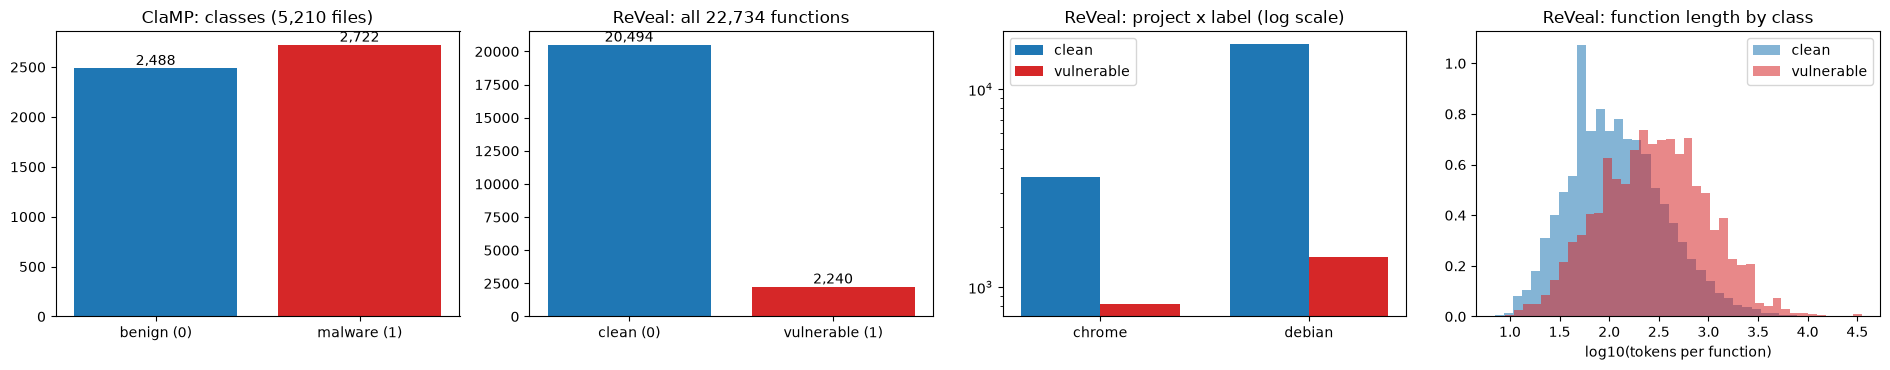

ClaMP  training rows plotted: 1824 (proportion 0.5, seed 42); PCA(16) explained variance 0.43


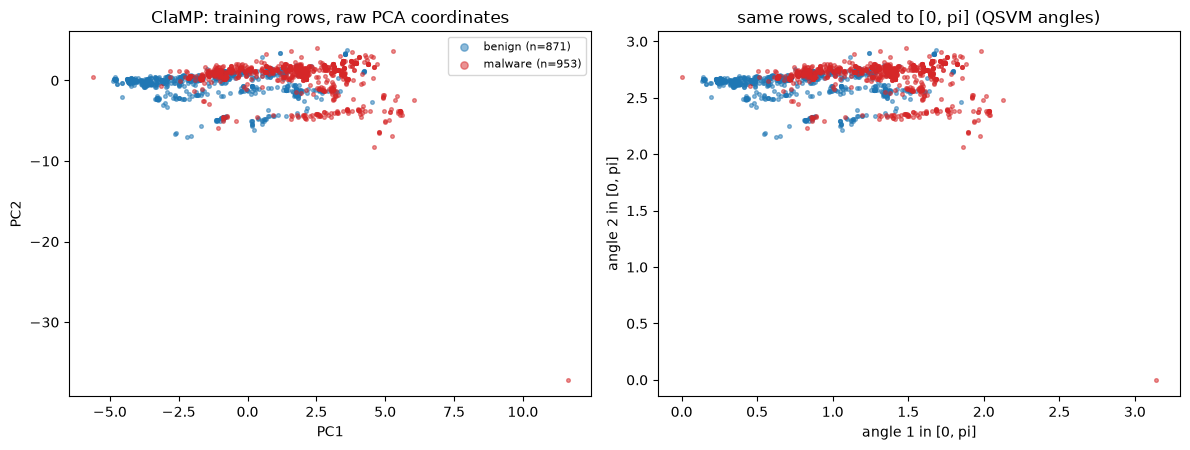

ReVeal training rows plotted: 1568 (proportion 0.5, seed 42); PCA(16) explained variance 0.99


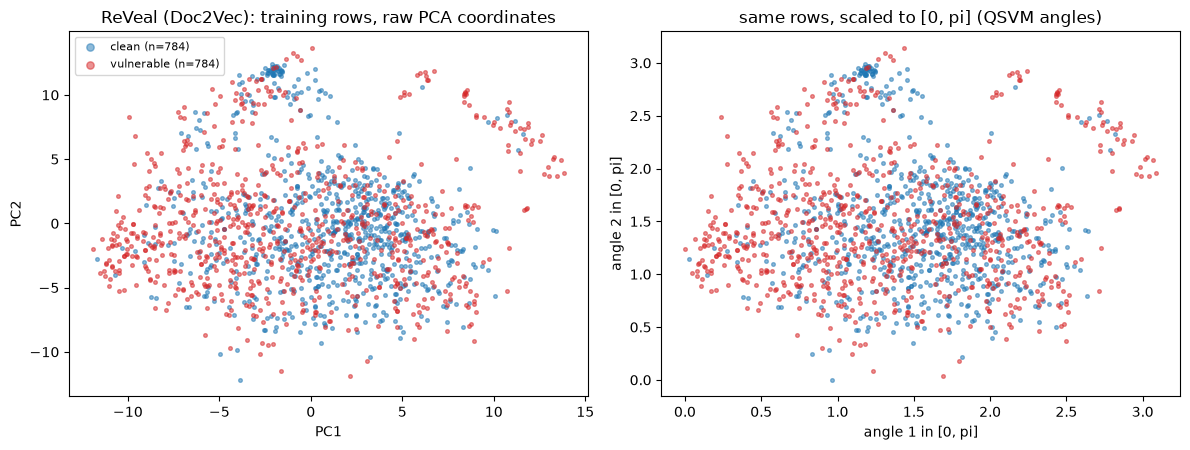

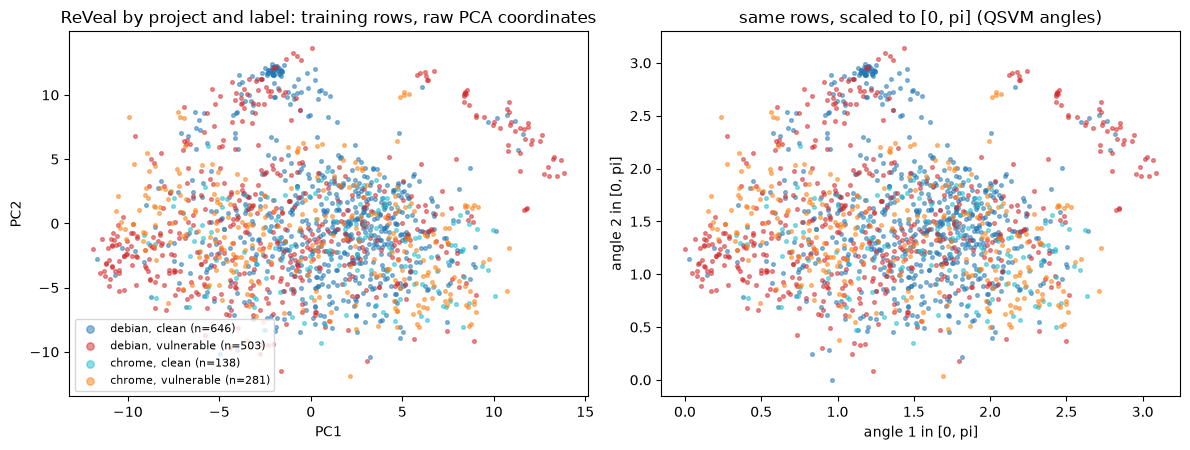

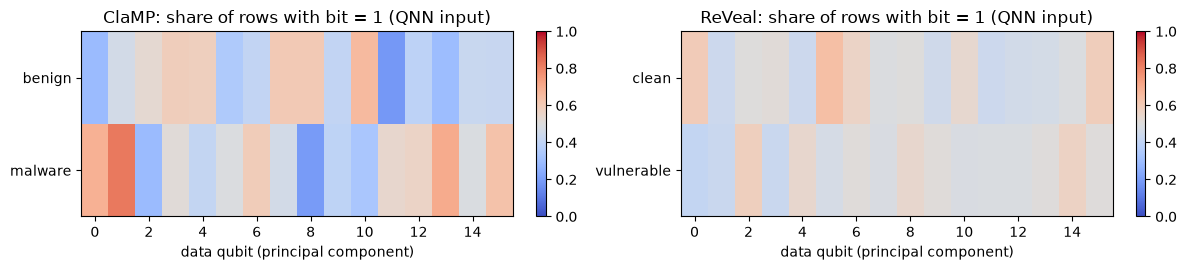

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
c = clamp["class"].value_counts().sort_index()
axes[0].bar(["benign (0)", "malware (1)"], c.values, color=["tab:blue", "tab:red"]); axes[0].set_title("ClaMP: classes (5,210 files)")
for i, v in enumerate(c.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
c = reveal_raw["label"].value_counts().sort_index()
axes[1].bar(["clean (0)", "vulnerable (1)"], c.values, color=["tab:blue", "tab:red"]); axes[1].set_title("ReVeal: all 22,734 functions")
for i, v in enumerate(c.values): axes[1].text(i, v, f"{v:,}", ha="center", va="bottom")
ct = pd.crosstab(reveal_raw["project"], reveal_raw["label"])
x = np.arange(len(ct)); w = 0.38
axes[2].bar(x - w / 2, ct[0].values, w, color="tab:blue", label="clean"); axes[2].bar(x + w / 2, ct[1].values, w, color="tab:red", label="vulnerable")
axes[2].set_xticks(x); axes[2].set_xticklabels(ct.index); axes[2].set_yscale("log"); axes[2].legend(); axes[2].set_title("ReVeal: project x label (log scale)")
for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
    axes[3].hist(np.log10(toklen[reveal_raw.label == lab]), bins=40, alpha=0.55, color=col, density=True, label=["clean", "vulnerable"][lab])
axes[3].set_xlabel("log10(tokens per function)"); axes[3].legend(); axes[3].set_title("ReVeal: function length by class")
plt.tight_layout(); plt.show()

def scatter_pair(d, title, group=None, group_names=None, colors=None):
    """left: raw PCA coordinates (PCA fitted on the training split); right: the same two coordinates scaled to [0, pi] (angle encoding)"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    labels = group if group is not None else d["ytr"]
    names = group_names or {0: ("benign" if d["name"] == "ClaMP" else "clean"), 1: ("malware" if d["name"] == "ClaMP" else "vulnerable")}
    colors = colors or {0: "tab:blue", 1: "tab:red"}
    for k in sorted(names):
        m = labels == k
        axes[0].scatter(d["Ptr"][m, 0], d["Ptr"][m, 1], s=7, alpha=0.5, color=colors[k], label=f"{names[k]} (n={m.sum()})")
        axes[1].scatter(d["Atr"][m, 0], d["Atr"][m, 1], s=7, alpha=0.5, color=colors[k])
    axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].set_title(f"{title}: training rows, raw PCA coordinates")
    axes[1].set_xlabel("angle 1 in [0, pi]"); axes[1].set_ylabel("angle 2 in [0, pi]"); axes[1].set_title("same rows, scaled to [0, pi] (QSVM angles)")
    axes[0].legend(fontsize=8, markerscale=2); plt.tight_layout(); plt.show()

dc, dr = main["ClaMP"], main["ReVeal"]
print(f"ClaMP  training rows plotted: {len(dc['ytr'])} (proportion {MAIN_P}, seed {SEED}); PCA(16) explained variance {dc['explained']:.2f}")
scatter_pair(dc, "ClaMP")
print(f"ReVeal training rows plotted: {len(dr['ytr'])} (proportion {MAIN_P}, seed {SEED}); PCA(16) explained variance {dr['explained']:.2f}")
scatter_pair(dr, "ReVeal (Doc2Vec)")
proj = bal_main["project"].values[dr["idx_tr"]]
grp = np.where(proj == "debian", 0, 2) + bal_main["label"].values[dr["idx_tr"]]          # four ground-truth groups: project x label
scatter_pair(dr, "ReVeal by project and label", group=grp,
             group_names={0: "debian, clean", 1: "debian, vulnerable", 2: "chrome, clean", 3: "chrome, vulnerable"},
             colors={0: "tab:blue", 1: "tab:red", 2: "tab:cyan", 3: "tab:orange"})

# the 16 bits the QNN sees: share of rows with bit = 1, per class
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
for ax, d in zip(axes, (dc, dr)):
    rate = np.array([d["Btr"][d["ytr"] == k].mean(0) for k in (0, 1)])
    im = ax.imshow(rate, aspect="auto", cmap="coolwarm", vmin=0, vmax=1); ax.set_yticks([0, 1])
    ax.set_yticklabels(["benign" if d["name"] == "ClaMP" else "clean", "malware" if d["name"] == "ClaMP" else "vulnerable"])
    ax.set_xlabel("data qubit (principal component)"); ax.set_title(f"{d['name']}: share of rows with bit = 1 (QNN input)"); fig.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Three quantum architectures appear in the paper and in this notebook, and each one is built, drawn and counted here exactly as it is executed:

1. **QNN.** The TensorFlow-Quantum model circuit rebuilt in PennyLane (17 qubits: 16 data qubits and one readout qubit, 32 trainable angles).
   Training uses an exact closed form of this circuit that is asserted equal to the circuit (outputs and gradients).
2. **Hybrid QNNs.** The *same* parameterised circuit as 1 followed by a small classical layer on its single output (45 and 63 parameters in total).
3. **QSVM.** The Qiskit `zz_feature_map` on 16 qubits (no trainable parameters); the kernel entry of two samples is the squared overlap of their
   feature states. A vectorised simulator computes the Gram matrices and is asserted equal to Qiskit's `Statevector` and `FidelityStatevectorKernel`.

The paper does not print circuit details beyond its Figures 5 and 6 (a data circuit of qubits with X gates and a two-layer model circuit),
so the gate layout of the QNN follows the TensorFlow-Quantum tutorial that the paper's description matches step by step; the QSVM feature map is not stated
and is our choice (ZZ feature map, 2 repetitions, linear entanglement).

device: lightning.qubit | wires: 17 | differentiation: adjoint
QNN: first ClaMP training row, label 1, bits = [1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1]


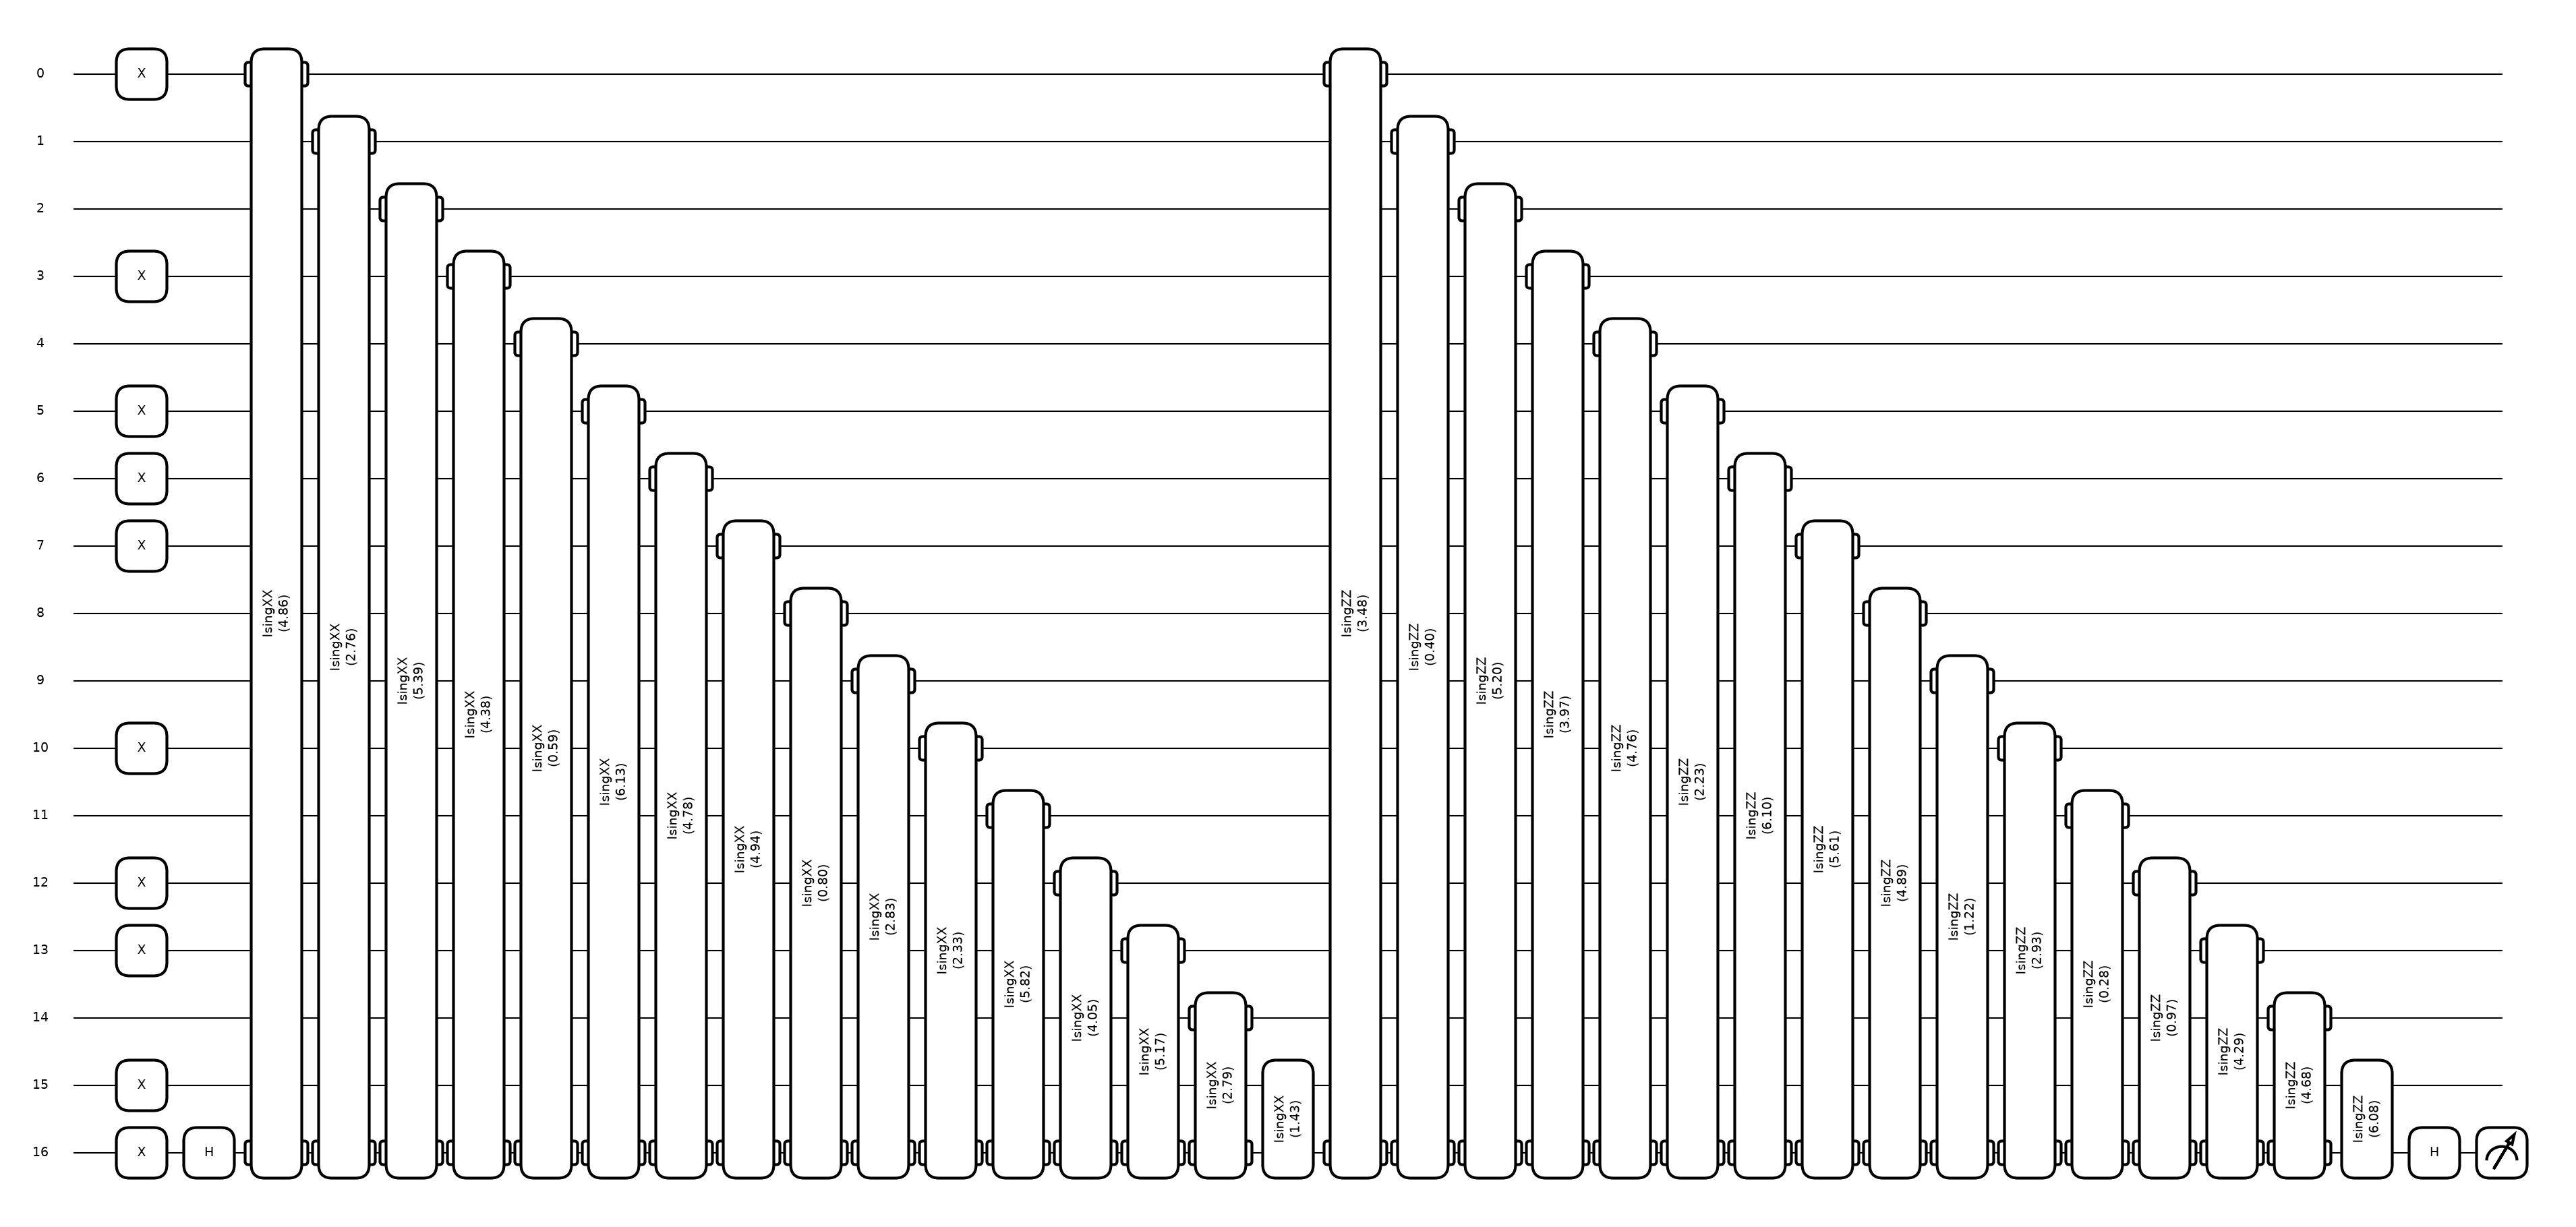

QNN  | qubits 17 (16 data + 1 readout) | depth 35 | gates 44 | trainable parameters 32 (16 XX angles + 16 ZZ angles)


circuit outputs  : [-0.049267  0.048199 -0.046912  0.066797  0.057293  0.066963  0.036883
  0.068763]
closed form      : [-0.049267  0.048199 -0.046912  0.066797  0.057293  0.066963  0.036883
  0.068763]
max |difference| : outputs 8.5e-16, grad theta 1.5e-16, grad phi 1.1e-15
hinge-loss gradient on 8 rows: circuit 3.51 s (438 ms/row), closed form 9.7 ms (1.21 ms/row)
Hybrid-QNN_V1: same 17-qubit circuit as the QNN (drawing above) -> Dense(4, ReLU) -> Dense(1); trainable parameters 45 (paper: 45)
Hybrid-QNN_V2: same 17-qubit circuit as the QNN (drawing above) -> Dense(10, ReLU) -> Dense(1); trainable parameters 63 (paper: 63)


In [8]:
READOUT = N_QUBITS                                       # wire index of the readout qubit (data qubits are 0 ... 15)
try:
    dev = qml.device("lightning.qubit", wires=N_QUBITS + 1); DIFF_METHOD = "adjoint"
except Exception as e:                                   # pennylane-lightning missing: fall back to the reference simulator
    print("lightning.qubit unavailable (%s); using default.qubit" % type(e).__name__)
    dev = qml.device("default.qubit", wires=N_QUBITS + 1); DIFF_METHOD = "backprop"
print("device:", dev.name, "| wires:", N_QUBITS + 1, "| differentiation:", DIFF_METHOD)

@qml.qnode(dev, interface="autograd", diff_method=DIFF_METHOD)
def qnn_circuit(bits, theta, phi):
    """TFQ-tutorial QNN for one row: data circuit (X where bit = 1) + readout in |-> + XX layer + ZZ layer + H + <Z>."""
    for q in range(N_QUBITS):                            # data circuit (the paper's Figure 5)
        if bits[q] > 0.5:
            qml.PauliX(wires=q)
    qml.PauliX(wires=READOUT); qml.Hadamard(wires=READOUT)       # readout starts in |->
    for q in range(N_QUBITS):                            # model circuit layer 1: XX(theta_q) between data qubit q and the readout
        qml.IsingXX(theta[q], wires=[q, READOUT])
    for q in range(N_QUBITS):                            # layer 2: ZZ(phi_q)  (the paper's "two-layer model", Figure 6)
        qml.IsingZZ(phi[q], wires=[q, READOUT])
    qml.Hadamard(wires=READOUT)
    return qml.expval(qml.PauliZ(READOUT))

def qnn_closed_form(bits, theta, phi):
    """Exact <Z_readout> of qnn_circuit for a batch of bit rows:  -Re prod_q ( cos(phi_q) - i sin(phi_q) (-1)^b_q cos(theta_q) )."""
    sign = 1.0 - 2.0 * bits                                              # (-1)^bit, shape (batch, 16)
    z = pnp.cos(phi)[None, :] - 1j * pnp.sin(phi)[None, :] * sign * pnp.cos(theta)[None, :]
    return -pnp.real(pnp.prod(z, axis=1))

def hinge_loss(output, y_pm):
    """TFQ's Hinge loss with labels in {-1, +1}."""
    return pnp.mean(pnp.maximum(0.0, 1.0 - y_pm * output))

def qnn_cost_cf(theta, phi, bits, y_pm):                 # exact formula
    return hinge_loss(qnn_closed_form(bits, theta, phi), y_pm)

def qnn_cost_sim(theta, phi, bits, y_pm):                # 17-qubit simulation, one circuit per row
    return hinge_loss(pnp.stack([qnn_circuit(bits[i], theta, phi) for i in range(len(y_pm))]), y_pm)

def init_params(seed):
    """# CHOICE: angles uniform in [0, 2 pi), the default initialiser of TFQ's PQC layer."""
    r = np.random.default_rng(seed)
    return (pnp.array(r.uniform(0, 2 * np.pi, N_QUBITS), requires_grad=True),
            pnp.array(r.uniform(0, 2 * np.pi, N_QUBITS), requires_grad=True))

# ---- architecture 1: draw the circuit for a real training row of ClaMP ----
theta0, phi0 = init_params(SEED)
row = dc["Btr"][0]
print(f"QNN: first ClaMP training row, label {dc['ytr'][0]}, bits = {row.astype(int).tolist()}")
fig, ax = qml.draw_mpl(qnn_circuit, decimals=2)(row, theta0, phi0)
plt.show()
sp = qml.specs(qnn_circuit)(row, theta0, phi0)
print(f"QNN  | qubits {N_QUBITS + 1} (16 data + 1 readout) | depth {sp['resources'].depth} | gates {sp['resources'].num_gates} "
      f"| trainable parameters {theta0.size + phi0.size} (16 XX angles + 16 ZZ angles)")

# ---- equivalence: closed form == 17-qubit circuit (outputs and gradients) ----
b8, y8 = dc["Btr"][:8], 2.0 * dc["ytr"][:8] - 1.0
t0 = time.perf_counter(); out_sim = np.array([float(qnn_circuit(b8[i], theta0, phi0)) for i in range(8)]); t_fwd = time.perf_counter() - t0
out_cf = np.asarray(qnn_closed_form(b8, theta0, phi0))
t0 = time.perf_counter(); g_sim = qml.grad(qnn_cost_sim, argnums=[0, 1])(theta0, phi0, b8, y8); t_gsim = time.perf_counter() - t0
t0 = time.perf_counter(); g_cf = qml.grad(qnn_cost_cf, argnums=[0, 1])(theta0, phi0, b8, y8); t_gcf = time.perf_counter() - t0
print("circuit outputs  :", np.round(out_sim, 6))
print("closed form      :", np.round(out_cf, 6))
print("max |difference| : outputs %.1e, grad theta %.1e, grad phi %.1e" % (
      np.abs(out_sim - out_cf).max(), np.abs(np.asarray(g_sim[0]) - np.asarray(g_cf[0])).max(), np.abs(np.asarray(g_sim[1]) - np.asarray(g_cf[1])).max()))
assert np.allclose(out_sim, out_cf, atol=1e-8) and all(np.allclose(a, b, atol=1e-8) for a, b in zip(g_sim, g_cf))
SIM_MS_PER_ROW, CF_MS_PER_ROW = 1000 * t_gsim / 8, 1000 * t_gcf / 8
print(f"hinge-loss gradient on 8 rows: circuit {t_gsim:.2f} s ({SIM_MS_PER_ROW:.0f} ms/row), closed form {1000 * t_gcf:.1f} ms ({CF_MS_PER_ROW:.2f} ms/row)")

# ---- architecture 2: the hybrids reuse this circuit; their parameter counts ----
def hybrid_param_count(h): return 2 * N_QUBITS + (h + h) + (h + 1)        # PQC angles + Dense(1->h) + Dense(h->1)
for h, name in [(4, "Hybrid-QNN_V1"), (10, "Hybrid-QNN_V2")]:
    print(f"{name}: same 17-qubit circuit as the QNN (drawing above) -> Dense({h}, ReLU) -> Dense(1); trainable parameters "
          f"{hybrid_param_count(h)} (paper: {45 if h == 4 else 63})")

QSVM feature map: first ClaMP training row, label 1, angles = [1.59, 2.58, 0.39, 1.73, 0.26, 0.95, 0.42, 1.64, 0.63, 0.91, 0.81, 1.61, 2.46, 1.45, 0.53, 1.27]


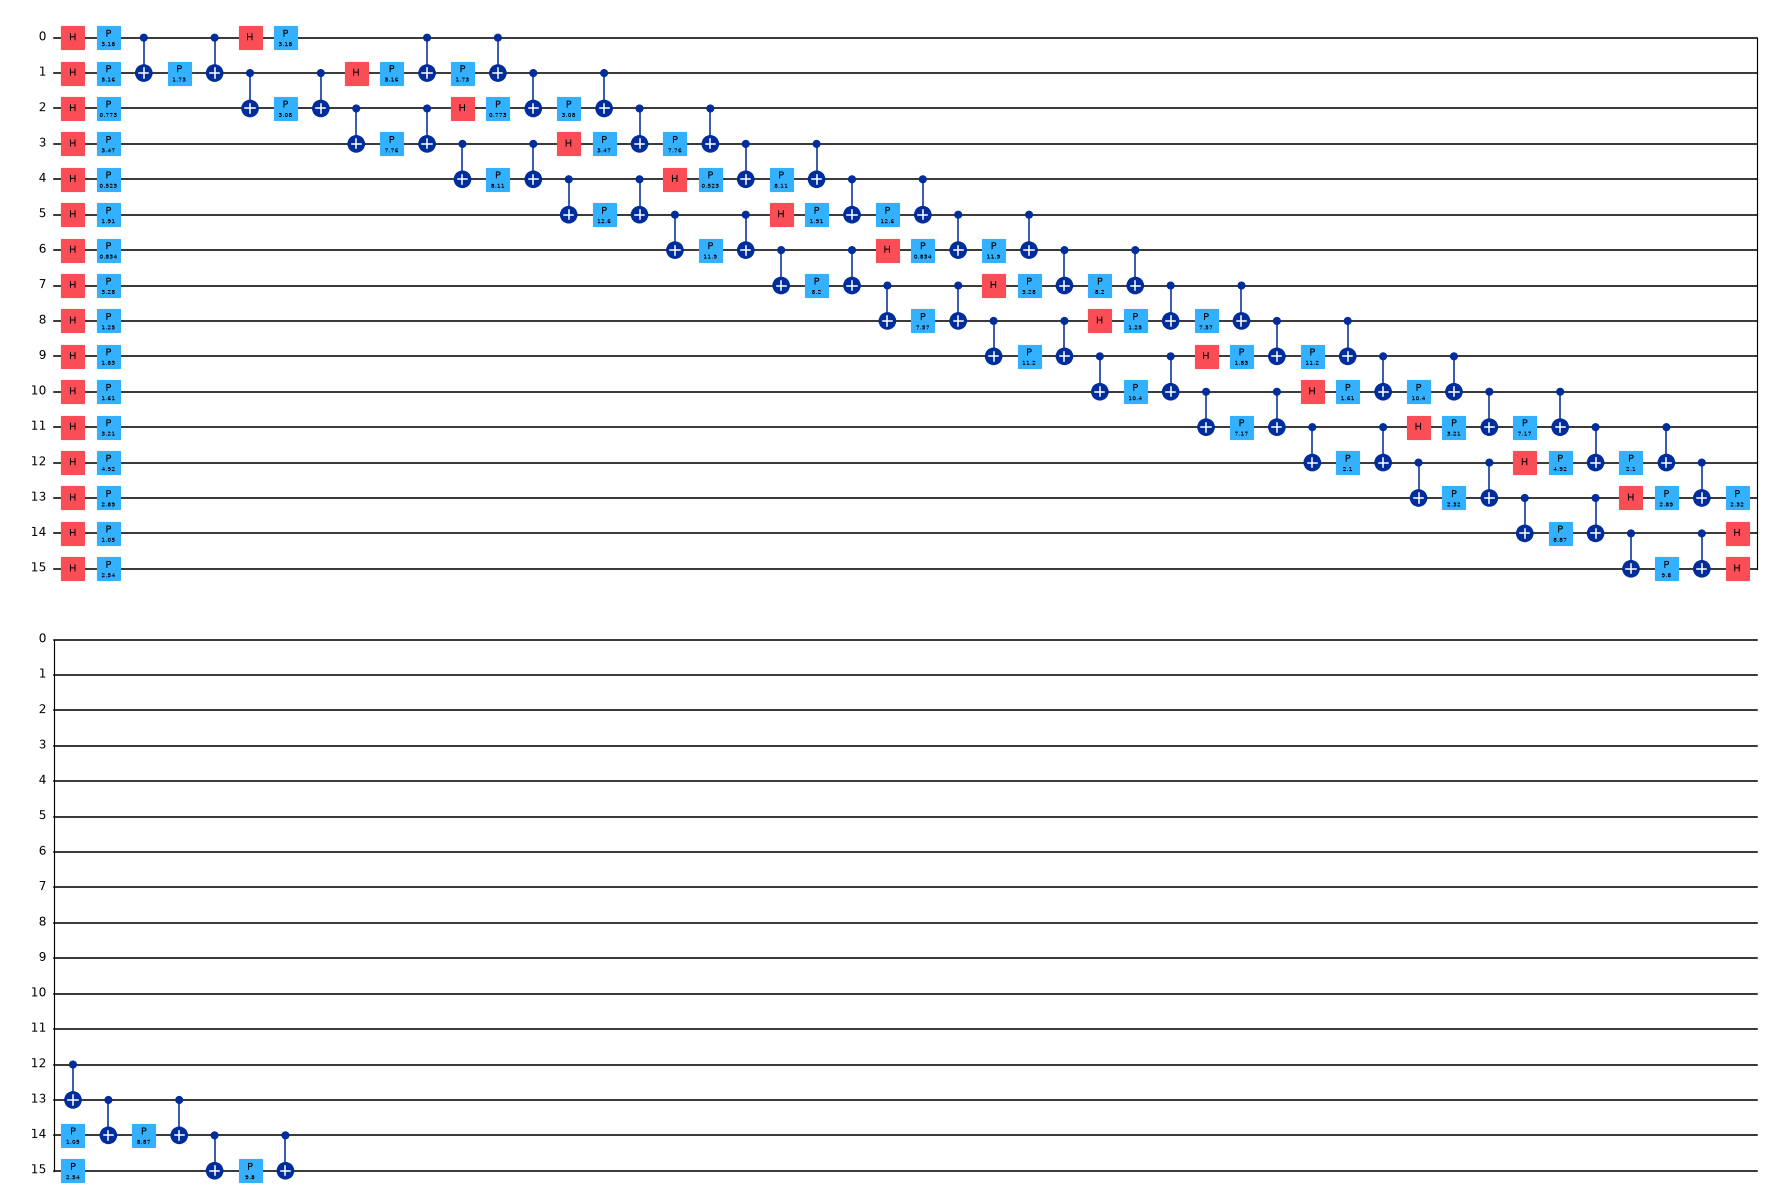

QSVM | qubits 16 | depth 55 (gates h/p/cx: {'p': 62, 'cx': 60, 'h': 32}) | feature parameters 16 (one per qubit) | trainable circuit parameters 0 (the SVM weights are fitted classically)
fidelity-kernel circuit U(x2)^dagger U(x1): 16 qubits, depth 110; the kernel entry is the probability of measuring all zeros, |<phi(x2)|phi(x1)>|^2


max |amplitude difference| between Qiskit Statevector and the vectorised simulator on 5 rows: complex128 9.5e-16, complex64 (used for the Gram matrices) 3.6e-08


In [9]:
# ---- architecture 3: the QSVM feature map, executed as in Qiskit and as in the vectorised simulator ----
from qiskit import transpile
FM = zz_feature_map(N_QUBITS, reps=2, entanglement="linear")                     # CHOICE: the paper does not state the feature map
a0 = dc["Atr"][0]
fm_bound = FM.assign_parameters(a0)
fm_basis = transpile(fm_bound, basis_gates=["h", "p", "cx"], optimization_level=0)      # the gate list that is actually simulated
print(f"QSVM feature map: first ClaMP training row, label {dc['ytr'][0]}, angles = {np.round(a0, 2).tolist()}")
fig = fm_basis.draw("mpl", fold=48, scale=0.55)
display(fig)
print(f"QSVM | qubits {FM.num_qubits} | depth {fm_basis.depth()} (gates h/p/cx: {dict(fm_basis.count_ops())}) | feature parameters {FM.num_parameters} "
      f"(one per qubit) | trainable circuit parameters 0 (the SVM weights are fitted classically)")
kernel_circ = fm_bound.compose(FM.assign_parameters(dc["Atr"][1]).inverse())
print(f"fidelity-kernel circuit U(x2)^dagger U(x1): {kernel_circ.num_qubits} qubits, depth {transpile(kernel_circ, basis_gates=['h','p','cx'], optimization_level=0).depth()}; "
      "the kernel entry is the probability of measuring all zeros, |<phi(x2)|phi(x1)>|^2")

# ---- vectorised exact simulator of this circuit: ZZ map = (diagonal phase D) H (diagonal phase D) H |0...0>, rep by rep ----
DIM = 2 ** N_QUBITS
_idx = np.arange(DIM)
ZBITS = ((_idx[:, None] >> np.arange(N_QUBITS)) & 1).astype(np.float64)              # basis state z: qubit i is bit i (Qiskit's little-endian order)
PAIRS = [(i, i + 1) for i in range(N_QUBITS - 1)]                                    # linear entanglement
ZXOR = np.stack([(ZBITS[:, i] != ZBITS[:, j]).astype(np.float64) for i, j in PAIRS], 1)
ZBITS_T, ZXOR_T = np.ascontiguousarray(ZBITS.T), np.ascontiguousarray(ZXOR.T)
_H8 = np.array([[1.0]])
for _ in range(8): _H8 = np.block([[_H8, _H8], [_H8, -_H8]])                          # Sylvester-Hadamard matrix of order 256 = H on 8 qubits (unnormalised)
H8N = _H8 / 16.0                                                                      # normalised

def zz_phases(X):
    """phase of the diagonal part for every basis state: sum_i 2 x_i z_i + sum_(i,j) 2 (pi - x_i)(pi - x_j) [z_i xor z_j]"""
    X = np.asarray(X, dtype=np.float64)
    return 2 * X @ ZBITS_T + (2 * (np.pi - X[:, :-1]) * (np.pi - X[:, 1:])) @ ZXOR_T

def hadamard_all(a):
    """H on all 16 qubits: a (batch, 65536) vector is a 256 x 256 matrix per sample and H(x)H(x)... = H8 @ M @ H8 (normalised, real matrices)."""
    B = a.shape[0]; dt = np.float32 if a.dtype == np.complex64 else np.float64
    H = H8N.astype(dt)
    m = a.reshape(B, 256, 256)
    re, im = H @ m.real @ H, H @ m.imag @ H
    out = np.empty(a.shape, dtype=a.dtype).reshape(B, 256, 256)
    out.real, out.imag = re, im
    return out.reshape(B, DIM)

def zz_states(X, dtype=np.complex128):
    """exact feature states |phi(x)> of zz_feature_map(16, reps=2, entanglement='linear') for a batch X (rows are angles):  D H D H|0>"""
    ph = zz_phases(X)
    e = np.exp(1j * (np.mod(ph, 2 * np.pi).astype(np.float32 if dtype == np.complex64 else np.float64)))   # float32 only after reducing the phase mod 2 pi
    e = e.astype(dtype, copy=False)
    return e * hadamard_all(e * dtype(2.0 ** (-N_QUBITS / 2)))

rows_chk = np.vstack([dc["Atr"][:3], np.random.default_rng(1).uniform(0, np.pi, (2, N_QUBITS))])
ref = [Statevector(FM.assign_parameters(x)).data for x in rows_chk]
err64 = max(np.abs(r - zz_states(x[None])[0]).max() for r, x in zip(ref, rows_chk))
err32 = max(np.abs(r - zz_states(x[None], np.complex64)[0]).max() for r, x in zip(ref, rows_chk))
print(f"max |amplitude difference| between Qiskit Statevector and the vectorised simulator on 5 rows: complex128 {err64:.1e}, complex64 (used for the Gram matrices) {err32:.1e}")
assert err64 < 1e-10 and err32 < 1e-5

## 3. The kernel: exact fidelity Gram matrices for the QSVM

The QSVM is an ordinary SVM whose kernel is the overlap of two quantum feature states, K(a, b) = |<phi(a)|phi(b)>|^2, with
phi the 16-qubit ZZ feature map drawn above. The state vector has 2^16 = 65,536 amplitudes, so one Gram matrix of n rows
is a product of an n x 65,536 complex matrix with its conjugate transpose. Three engineering points:

* **Exact, not sampled.** The paper does not say how many shots its simulator used; the exact statevector kernel is the
  limit of infinitely many shots.
* **Memory.** The training states (up to 3,647 x 65,536 complex numbers) do not fit in the RAM of a free Colab session, so they are
  written to a temporary file (`DATA_DIR`) and read back block by block; `complex64` is used for the product.
* **Bandwidth.** A quantum kernel with 16 qubits concentrates (all off-diagonal entries become tiny) unless the angles are shrunk,
  so the angle scale `gamma` is chosen on a validation split of the training data (`QSVM_GAMMAS`), together with C. The test set is never touched.

The check below compares our Gram matrix with Qiskit's own `FidelityStatevectorKernel` and the resulting classifier with Qiskit's `QSVC` on a small subset.

In [10]:
KERNEL_TMP = os.path.join(DATA_DIR, "zz_states_tmp.dat")
CHUNK, BLOCK, IN_MEMORY_MAX = 32, 256, 400

def states_c64(X):
    out = np.empty((len(X), DIM), dtype=np.complex64)
    for i in range(0, len(X), CHUNK): out[i:i + CHUNK] = zz_states(X[i:i + CHUNK], np.complex64)
    return out

def write_states(X, path=KERNEL_TMP):
    if len(X) <= IN_MEMORY_MAX: return states_c64(X)                          # small sets stay in RAM
    mm = np.memmap(path, dtype=np.complex64, mode="w+", shape=(len(X), DIM))
    for i in range(0, len(X), CHUNK): mm[i:i + CHUNK] = zz_states(X[i:i + CHUNK], np.complex64)
    mm.flush(); return mm

TIMERS = {"states": 0.0, "products": 0.0}                                      # seconds spent generating states / multiplying them

def fidelity_gram(XR, XL=None):
    """K[i, j] = |<phi(XL_i)|phi(XR_j)>|^2 for angle rows XL (default: XR itself, symmetric) and XR; exact statevector kernel."""
    sym = XL is None
    with threadpool_limits(limits=4):                                           # leave cores to other processes
        t0 = time.perf_counter(); S = write_states(XR); TIMERS["states"] += time.perf_counter() - t0
        nL = len(XR) if sym else len(XL)
        K = np.zeros((nL, len(XR)))
        for i in range(0, nL, BLOCK):
            t0 = time.perf_counter(); SL = np.asarray(S[i:i + BLOCK]) if sym else states_c64(XL[i:i + BLOCK]); TIMERS["products" if sym else "states"] += time.perf_counter() - t0
            for j in range(i if sym else 0, len(XR), BLOCK):
                t0 = time.perf_counter()
                P = SL @ np.asarray(S[j:j + BLOCK]).conj().T
                blk = P.real.astype(np.float64) ** 2 + P.imag.astype(np.float64) ** 2
                K[i:i + len(SL), j:j + blk.shape[1]] = blk
                if sym and j > i: K[j:j + blk.shape[1], i:i + len(SL)] = blk.T
                TIMERS["products"] += time.perf_counter() - t0
    if isinstance(S, np.memmap):
        del S; gc.collect()
        try: os.remove(KERNEL_TMP)
        except OSError: pass
    return K

# ---- check against Qiskit: Gram matrix and classifier on 12 training + 6 test rows (6 + 6 and 3 + 3 per class) ----
g_chk = 0.5
sel_tr = np.r_[np.where(dc["ytr"] == 0)[0][:6], np.where(dc["ytr"] == 1)[0][:6]]
sel_te = np.r_[np.where(dc["yte"] == 0)[0][:3], np.where(dc["yte"] == 1)[0][:3]]
Xs, ys, Xt = g_chk * dc["Atr"][sel_tr], dc["ytr"][sel_tr], g_chk * dc["Ate"][sel_te]
t0 = time.perf_counter(); K_ours, K_ours_t = fidelity_gram(Xs), fidelity_gram(Xs, XL=Xt); t_ours = time.perf_counter() - t0
qk = FidelityStatevectorKernel(feature_map=FM, auto_clear_cache=False)
t0 = time.perf_counter(); K_q, K_qt = qk.evaluate(Xs), qk.evaluate(Xt, Xs); t_q = time.perf_counter() - t0
print(f"Gram matrices on {len(Xs)} + {len(Xt)} rows: max |ours - Qiskit FidelityStatevectorKernel| = {max(np.abs(K_ours - K_q).max(), np.abs(K_ours_t - K_qt).max()):.1e}"
      f" (ours {t_ours:.1f} s, Qiskit {t_q:.1f} s)")
assert np.abs(K_ours - K_q).max() < 1e-5 and np.abs(K_ours_t - K_qt).max() < 1e-5
qsvc = QSVC(quantum_kernel=qk, C=1.0).fit(Xs, ys)
pred_qsvc, pred_ours = qsvc.predict(Xt), SVC(kernel="precomputed", C=1.0).fit(K_ours, ys).predict(K_ours_t)
print("Qiskit QSVC predictions:", pred_qsvc.tolist(), "| our precomputed-kernel SVC:", pred_ours.tolist(), "| identical:", bool(np.array_equal(pred_qsvc, pred_ours)))
assert np.array_equal(pred_qsvc, pred_ours)

Gram matrices on 12 + 6 rows: max |ours - Qiskit FidelityStatevectorKernel| = 7.2e-07 (ours 2.0 s, Qiskit 35.4 s)


Qiskit QSVC predictions: [0, 1, 0, 1, 0, 1] | our precomputed-kernel SVC: [0, 1, 0, 1, 0, 1] | identical: True


## 4. Models and metrics

* **QNN** and the two **hybrids** train through the exact closed form (verified above against the 17-qubit circuit) with Adam on the
  hinge loss, labels -1 / +1, 20 epochs, mini-batches of 32; the prediction is class 1 (malware / vulnerable) when the output is positive.
  The hybrid feeds the QNN's single output through a classical layer: `Dense(h, ReLU)` then `Dense(1)`, h = 4 or 10.
* **Classical SVM** (RBF, C = 1) and **classical NNs** (scikit-learn `MLPClassifier`, Adam, batch 32, 20 epochs; 16-8-4-1 = 177 parameters; "fair" 16-4-1 = 73 on ClaMP, 16-3-1 = 55 on ReVeal) use the 16 principal components, as in the paper.
* **QSVM** uses the angle-encoded components, the exact fidelity kernel, and a bandwidth chosen on the training data.
* **Extra baselines (not in the paper)** on exactly the quantum models' inputs: a random forest on the 16 PCs; an RBF-SVM on the QSVM's angles; SVM, NN and random forest on the QNN's 16 bits.

All metrics use malware / vulnerable as the positive class. "Execution time" is wall-clock training + prediction on this machine
(for the QSVM: the Gram matrices of the final fit plus the SVM fit and prediction; the bandwidth search is reported separately).

In [11]:
def metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, pos_label=1, zero_division=0),
                recall=recall_score(y_true, y_pred, pos_label=1, zero_division=0), f1=f1_score(y_true, y_pred, pos_label=1, zero_division=0),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def n_params(mlp): return int(sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))

# ---------------- QNN and hybrids ----------------
def train_qnn(bits, y, seed, epochs=EPOCHS):
    """Adam on mini-batches of the hinge loss, labels -1/+1; returns (theta, phi, full-training-set hinge loss after every epoch)."""
    theta, phi = init_params(seed)
    r = np.random.default_rng(seed + 1000)                              # batch order
    opt = qml.AdamOptimizer(stepsize=LR)
    bits = np.asarray(bits, dtype=float); y_pm = 2.0 * np.asarray(y, dtype=float) - 1.0
    losses = []
    for ep in range(epochs):
        perm = r.permutation(len(y_pm))
        for i in range(0, len(y_pm), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            theta, phi, _, _ = opt.step(qnn_cost_cf, theta, phi, bits[b], y_pm[b])
        losses.append(float(qnn_cost_cf(theta, phi, bits, y_pm)))
    return (theta, phi), losses

def qnn_predict(params, bits):
    return (np.asarray(qnn_closed_form(np.asarray(bits, dtype=float), *params)) > 0).astype(int)

def hybrid_forward(theta, phi, W1, b1, W2, b2, bits):
    g = qnn_closed_form(bits, theta, phi)                                # (batch,) QNN output in [-1, 1]
    a = pnp.maximum(0.0, g[:, None] * W1[None, :] + b1[None, :])         # Dense(h, ReLU) on the single QNN output
    return a @ W2 + b2[0]                                                # Dense(1)

def hybrid_cost(theta, phi, W1, b1, W2, b2, bits, y_pm):
    return hinge_loss(hybrid_forward(theta, phi, W1, b1, W2, b2, bits), y_pm)

def train_hybrid(bits, y, seed, h, epochs=EPOCHS):
    theta, phi = init_params(seed)
    r0 = np.random.default_rng(seed + 7)                                 # CHOICE: Keras defaults, Glorot-uniform weights and zero biases
    l1, l2 = math.sqrt(6.0 / (1 + h)), math.sqrt(6.0 / (h + 1))
    W1 = pnp.array(r0.uniform(-l1, l1, h), requires_grad=True); b1 = pnp.array(np.zeros(h), requires_grad=True)
    W2 = pnp.array(r0.uniform(-l2, l2, h), requires_grad=True); b2 = pnp.array(np.zeros(1), requires_grad=True)
    r = np.random.default_rng(seed + 1000); opt = qml.AdamOptimizer(stepsize=LR)
    bits = np.asarray(bits, dtype=float); y_pm = 2.0 * np.asarray(y, dtype=float) - 1.0
    losses = []
    for ep in range(epochs):
        perm = r.permutation(len(y_pm))
        for i in range(0, len(y_pm), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            theta, phi, W1, b1, W2, b2, _, _ = opt.step(hybrid_cost, theta, phi, W1, b1, W2, b2, bits[b], y_pm[b])
        losses.append(float(hybrid_cost(theta, phi, W1, b1, W2, b2, bits, y_pm)))
    return (theta, phi, W1, b1, W2, b2), losses

def hybrid_predict(params, bits):
    return (np.asarray(hybrid_forward(*params, np.asarray(bits, dtype=float))) > 0).astype(int)

# ---------------- classical models ----------------
def classical_models(seed, ds):
    fair_h = 4 if ds == "ClaMP" else 3                                   # CHOICE: 73 parameters on ClaMP (paper), 55 on ReVeal (paper: 51)
    return {"SVM": SVC(kernel="rbf", C=1.0, random_state=seed),
            "NN": MLPClassifier(hidden_layer_sizes=(8, 4), max_iter=EPOCHS, batch_size=BATCH_SIZE, random_state=seed),      # 177 parameters
            "NN-Fair": MLPClassifier(hidden_layer_sizes=(fair_h,), max_iter=EPOCHS, batch_size=BATCH_SIZE, random_state=seed),
            "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed)}

# ---------------- QSVM ----------------
def tune_qsvm(A, y, seed):
    """pick the angle scale gamma and C on a validation split of the TRAINING rows only"""
    n = min(QSVM_TUNE_N, len(y))
    sub = train_test_split(np.arange(len(y)), train_size=n, stratify=y, random_state=seed)[0] if n < len(y) else np.arange(len(y))
    fit, val = train_test_split(sub, test_size=0.3, stratify=y[sub], random_state=seed)
    table = []
    for g in QSVM_GAMMAS:
        Kf = fidelity_gram(g * A[fit]); Kv = fidelity_gram(g * A[fit], XL=g * A[val])
        offdiag = (Kf.sum() - np.trace(Kf)) / (len(fit) * (len(fit) - 1))
        for C in QSVM_CS:
            table.append(dict(gamma=g, C=C, val_accuracy=SVC(kernel="precomputed", C=C).fit(Kf, y[fit]).score(Kv, y[val]), mean_offdiag_kernel=offdiag))
    tab = pd.DataFrame(table)
    best = tab.loc[tab["val_accuracy"].idxmax()]                          # first maximum (smaller gamma, smaller C) on ties
    return float(best["gamma"]), float(best["C"]), tab

def subsample(pos, y, n, seed):
    """stratified cap of the positions `pos` to n rows (None = keep all)"""
    if n is None or len(pos) <= n: return pos
    return np.sort(pos[train_test_split(np.arange(len(pos)), train_size=n, stratify=y[pos], random_state=seed)[0]])

def qsvm_block(ds, seed):
    """One kernel computation per (dataset, seed) serves every proportion: bandwidth search on training rows, then the Gram matrix of all
    needed training rows and of the test rows against them; each proportion uses the sub-matrices of its own rows."""
    b = get_base(ds, seed)
    sel = {}
    for p in PROPORTIONS:
        d = get_data(ds, p, seed)
        sel[p] = (subsample(d["ptr"], b["ytr"], QSVM_MAX_TRAIN, seed), subsample(d["pte"], b["yte"], QSVM_MAX_TEST, seed))
    rows_tr = np.unique(np.concatenate([v[0] for v in sel.values()])); rows_te = np.unique(np.concatenate([v[1] for v in sel.values()]))
    A, y = b["Atr"][rows_tr], b["ytr"][rows_tr]
    t0 = time.perf_counter(); gamma, C, tune = tune_qsvm(A, y, seed); t_tune = time.perf_counter() - t0
    TIMERS["states"] = TIMERS["products"] = 0.0
    t0 = time.perf_counter(); Ktr = fidelity_gram(gamma * A); Kte = fidelity_gram(gamma * A, XL=gamma * b["Ate"][rows_te]); t_kernel = time.perf_counter() - t0
    T_states, T_prod = TIMERS["states"], TIMERS["products"]
    N1, N2 = len(rows_tr), len(rows_te)
    info = dict(gamma=gamma, C=C, rows_train=N1, rows_test=N2, tune_s=t_tune, kernel_s=t_kernel, states_s=T_states, products_s=T_prod,
                diag_dev=float(np.abs(np.diag(Ktr) - 1).max()), mean_offdiag=float((Ktr.sum() - np.trace(Ktr)) / (N1 * (N1 - 1))))
    out = []
    for p in PROPORTIONS:
        ptr, pte = sel[p]
        i_tr, i_te = np.searchsorted(rows_tr, ptr), np.searchsorted(rows_te, pte)
        t0 = time.perf_counter(); svc = SVC(kernel="precomputed", C=C).fit(Ktr[np.ix_(i_tr, i_tr)], b["ytr"][ptr]); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = svc.predict(Kte[np.ix_(i_te, i_tr)]); t_pred = time.perf_counter() - t0
        n1, n2 = len(ptr), len(pte)                                  # the part of the kernel work that this size needs (equal to the measured total for the largest size)
        f_states, f_prod = (n1 + n2) / (N1 + N2), (n1 * (n1 + 1) / 2 + n1 * n2) / (N1 * (N1 + 1) / 2 + N1 * N2)
        out.append(dict(p=p, n_train=n1, n_test=n2, y_true=b["yte"][pte], pred=pred, fit_s=T_states * f_states + T_prod * f_prod + t_fit,
                        predict_s=t_pred, n_support=int(svc.n_support_.sum())))
    return out, info, tune

## 5. Running the paper's protocol

For every dataset, proportion and seed the next cell trains the paper's seven models (QNN, two hybrids, NN, NN-fair, SVM; the QSVM follows in its own cell
because of its cost) plus the extra baselines, and stores accuracy, precision, recall, F1, the confusion counts, the parameter count and the execution time.
Each (dataset, proportion, seed) uses its own split, Doc2Vec model, scaler, PCA and initial angles.

In [12]:
records, preds, loss_curves = [], {}, {}

def add(ds, p, seed, model, inputs, d, fit_s, pred_s, y_pred, params=None):
    records.append(dict(dataset=ds, proportion=p, seed=seed, model=model, inputs=inputs, n_train=len(d["ytr"]), n_test=len(d["yte"]),
                        params=params, time_s=fit_s + pred_s, fit_s=fit_s, predict_s=pred_s, **metrics(d["yte"], y_pred)))
    preds[(ds, p, seed, model, inputs)] = (d["yte"], y_pred)

t_all = time.time()
for ds in BUILDERS:
    for p in PROPORTIONS:
        t_p = time.time()
        for seed in SEEDS:
            d = get_data(ds, p, seed)
            # --- classical models on the 16 principal components (the paper's classical inputs) ---
            for name, model in classical_models(seed, ds).items():
                t0 = time.perf_counter(); model.fit(d["Ptr"], d["ytr"]); t_fit = time.perf_counter() - t0
                t0 = time.perf_counter(); yp = model.predict(d["Pte"]); t_pred = time.perf_counter() - t0
                add(ds, p, seed, name, "16 PCs", d, t_fit, t_pred, yp, n_params(model) if hasattr(model, "coefs_") else None)
            # --- extra baselines on the quantum models' own inputs ---
            sv = SVC(kernel="rbf", C=1.0, random_state=seed)
            t0 = time.perf_counter(); sv.fit(d["Atr"], d["ytr"]); t_fit = time.perf_counter() - t0
            t0 = time.perf_counter(); yp = sv.predict(d["Ate"]); t_pred = time.perf_counter() - t0
            add(ds, p, seed, "SVM", "16 angles", d, t_fit, t_pred, yp)
            for name, model in classical_models(seed, ds).items():
                if name == "NN-Fair": continue
                t0 = time.perf_counter(); model.fit(d["Btr"], d["ytr"]); t_fit = time.perf_counter() - t0
                t0 = time.perf_counter(); yp = model.predict(d["Bte"]); t_pred = time.perf_counter() - t0
                add(ds, p, seed, name, "16 bits", d, t_fit, t_pred, yp, n_params(model) if hasattr(model, "coefs_") else None)
            # --- QNN ---
            t0 = time.perf_counter(); params, losses = train_qnn(d["Btr"], d["ytr"], seed); t_fit = time.perf_counter() - t0
            t0 = time.perf_counter(); yp = qnn_predict(params, d["Bte"]); t_pred = time.perf_counter() - t0
            add(ds, p, seed, "QNN", "16 bits", d, t_fit, t_pred, yp, 2 * N_QUBITS)
            if seed == SEED: loss_curves[(ds, p, "QNN")] = losses
            # --- hybrids ---
            for h, name in [(4, "Hybrid-QNN_V1"), (10, "Hybrid-QNN_V2")]:
                t0 = time.perf_counter(); params, losses = train_hybrid(d["Btr"], d["ytr"], seed, h); t_fit = time.perf_counter() - t0
                t0 = time.perf_counter(); yp = hybrid_predict(params, d["Bte"]); t_pred = time.perf_counter() - t0
                add(ds, p, seed, name, "16 bits", d, t_fit, t_pred, yp, hybrid_param_count(h))
                if seed == SEED: loss_curves[(ds, p, name)] = losses
        r = pd.DataFrame(records)
        r = r[(r.dataset == ds) & (r.proportion == p) & (r.inputs.isin(["16 PCs", "16 bits"]))]
        print(f"{ds:6s} proportion {p:4.2f}: " + ", ".join(f"{m} {100 * r[(r.model == m) & (r.inputs == i)].accuracy.mean():.1f}"
              for m, i in [("SVM", "16 PCs"), ("NN", "16 PCs"), ("QNN", "16 bits"), ("Hybrid-QNN_V1", "16 bits")]) + f"  | {time.time() - t_p:.0f} s", flush=True)
print(f"total: {(time.time() - t_all) / 60:.1f} min")

ClaMP  proportion 0.50: SVM 94.1, NN 92.6, QNN 73.1, Hybrid-QNN_V1 77.2  | 55 s


ReVeal proportion 0.50: SVM 60.9, NN 63.2, QNN 51.3, Hybrid-QNN_V1 50.3  | 61 s


total: 1.9 min


In [13]:
qsvm_records, qsvm_info, qsvm_tune = [], {}, {}
t_all = time.time()
for ds in BUILDERS:
    for seed in QSVM_SEEDS:
        out, info, tune = qsvm_block(ds, seed)
        qsvm_info[(ds, seed)], qsvm_tune[(ds, seed)] = info, tune
        print(f"{ds}: bandwidth gamma {info['gamma']}, C {info['C']} (search {info['tune_s']:.0f} s) | Gram matrices of {info['rows_train']} training and {info['rows_test']} test rows: "
              f"{info['kernel_s']:.0f} s (states {info['states_s']:.0f} s, products {info['products_s']:.0f} s) | mean off-diagonal kernel {info['mean_offdiag']:.3f} | max |K_ii - 1| {info['diag_dev']:.1e}", flush=True)
        for o in out:
            qsvm_records.append(dict(dataset=ds, proportion=o["p"], seed=seed, model="QSVM", inputs="16 angles", n_train=o["n_train"], n_test=o["n_test"], params=None,
                                     time_s=o["fit_s"] + o["predict_s"], fit_s=o["fit_s"], predict_s=o["predict_s"], **metrics(o["y_true"], o["pred"])))
            preds[(ds, o["p"], seed, "QSVM", "16 angles")] = (o["y_true"], o["pred"])
            print(f"   proportion {o['p']:4.2f}: {o['n_train']} train / {o['n_test']} test rows, QSVM accuracy {100 * qsvm_records[-1]['accuracy']:.1f} %, "
                  f"kernel + SVM time {qsvm_records[-1]['time_s']:.0f} s, support vectors {o['n_support']}", flush=True)
print(f"total: {(time.time() - t_all) / 60:.1f} min")
results = pd.DataFrame(records + qsvm_records)
results["accuracy_pct"] = 100 * results["accuracy"]

ClaMP: bandwidth gamma 0.5, C 10.0 (search 89 s) | Gram matrices of 300 training and 300 test rows: 73 s (states 58 s, products 15 s) | mean off-diagonal kernel 0.144 | max |K_ii - 1| 1.7e-06


   proportion 0.50: 300 train / 300 test rows, QSVM accuracy 91.0 %, kernel + SVM time 73 s, support vectors 85


ReVeal: bandwidth gamma 0.25, C 1.0 (search 91 s) | Gram matrices of 300 training and 300 test rows: 78 s (states 60 s, products 17 s) | mean off-diagonal kernel 0.012 | max |K_ii - 1| 1.2e-06


   proportion 0.50: 300 train / 300 test rows, QSVM accuracy 51.3 %, kernel + SVM time 77 s, support vectors 293

total: 5.5 min


## 6. The paper's Tables 2 and 3, re-computed

The tables below follow the paper's layout (model, parameters, accuracy, time) and add precision, recall and F1 with malware /
vulnerable as the positive class. They show the largest proportion of the run (`P_REF`: the entire dataset in the full protocol, 50 % in
`FAST_MODE`), mean +- standard deviation over the seeds. The paper's values are in the last two columns.

In [14]:
P_REF = max(PROPORTIONS)
ORDER = [("QNN", "16 bits"), ("Hybrid-QNN_V1", "16 bits"), ("Hybrid-QNN_V2", "16 bits"), ("NN", "16 PCs"), ("NN-Fair", "16 PCs"), ("QSVM", "16 angles"), ("SVM", "16 PCs")]
PAPER = {  # (parameters, accuracy %, time s): Table 2 (ClaMP, entire dataset) and Table 3 (ReVeal, entire dataset)
    "ClaMP":  {"QNN": (32, 52.1, 2698), "Hybrid-QNN_V1": (45, 52.27, 2581), "Hybrid-QNN_V2": (63, 52.27, 2507),
               "NN": (177, 92.7, 22), "NN-Fair": (73, 90.5, 19), "QSVM": (None, 73.5, 10000), "SVM": (None, 93.5, 1)},
    "ReVeal": {"QNN": (32, 52.71, 3006), "Hybrid-QNN_V1": (45, 52.71, 2999), "Hybrid-QNN_V2": (63, 52.71, 2563),
               "NN": (177, 55.7, 41), "NN-Fair": (51, 52.74, 20), "QSVM": (None, 58.26, 16682), "SVM": (None, 60.34, 2)}}

def pick(ds, model, inputs, p=None):
    p = P_REF if p is None else p
    return results[(results.dataset == ds) & (results.proportion == p) & (results.model == model) & (results.inputs == inputs)]

def ms(x, scale=100, nd=1):
    return f"{scale * x.mean():.{nd}f} +- {scale * x.std(ddof=0):.{nd}f}" if len(x) > 1 else f"{scale * x.mean():.{nd}f}"

def paper_table(ds):
    out = []
    for m, i in ORDER:
        g = pick(ds, m, i)
        par = PAPER[ds][m][0]
        out.append({"Model": m, "Parameters (ours / paper)": f"{int(g.params.iloc[0]) if g.params.notna().any() else '-'} / {par if par else '-'}",
                    "Accuracy % (ours)": ms(g.accuracy), "Precision": ms(g.precision, 1, 3), "Recall": ms(g.recall, 1, 3), "F1": ms(g.f1, 1, 3),
                    "Time s (ours)": ms(g.time_s, 1, 1), "Accuracy % (paper)": PAPER[ds][m][1], "Time s (paper)": PAPER[ds][m][2], "seeds": len(g)})
    return pd.DataFrame(out).set_index("Model")

for ds, tab in [("ClaMP", "Table 2"), ("ReVeal", "Table 3")]:
    g = pick(ds, "SVM", "16 PCs")
    print(f"\n{ds} - this notebook's {tab} (proportion {P_REF}: {int(g.n_train.iloc[0])} training / {int(g.n_test.iloc[0])} test rows; positive share of the test set "
          f"{100 * (g.tp.iloc[0] + g.fn.iloc[0]) / g.n_test.iloc[0]:.1f} %)")
    display(paper_table(ds))


ClaMP - this notebook's Table 2 (proportion 0.5: 1824 training / 782 test rows; positive share of the test set 52.3 %)


,Parameters (ours / paper),Accuracy % (ours),Precision,Recall,F1,Time s (ours),Accuracy % (paper),Time s (paper),seeds
Model,,,,,,,,,
QNN,32 / 32,73.1,0.748,0.733,0.741,9.9,52.10,2698,1
Hybrid-QNN_V1,45 / 45,77.2,0.757,0.831,0.793,16.0,52.27,2581,1
Hybrid-QNN_V2,63 / 63,78.1,0.759,0.853,0.803,15.5,52.27,2507,1
NN,177 / 177,92.6,0.929,0.929,0.929,1.9,92.70,22,1
NN-Fair,73 / 73,90.7,0.933,0.885,0.908,1.7,90.50,19,1
QSVM,- / -,91.0,0.939,0.885,0.911,72.9,73.50,10000,1
SVM,- / -,94.1,0.923,0.968,0.945,0.2,93.50,1,1



ReVeal - this notebook's Table 3 (proportion 0.5: 1568 training / 672 test rows; positive share of the test set 50.0 %)


,Parameters (ours / paper),Accuracy % (ours),Precision,Recall,F1,Time s (ours),Accuracy % (paper),Time s (paper),seeds
Model,,,,,,,,,
QNN,32 / 32,51.3,0.514,0.503,0.508,8.8,52.71,3006,1
Hybrid-QNN_V1,45 / 45,50.3,0.503,0.542,0.521,17.1,52.71,2999,1
Hybrid-QNN_V2,63 / 63,52.1,0.518,0.592,0.553,20.9,52.71,2563,1
NN,177 / 177,63.2,0.606,0.756,0.673,2.2,55.70,41,1
NN-Fair,55 / 51,58.9,0.566,0.768,0.652,1.6,52.74,20,1
QSVM,- / -,51.3,0.507,0.993,0.671,77.1,58.26,16682,1
SVM,- / -,60.9,0.573,0.848,0.684,0.7,60.34,2,1


**Extra baselines and the effect of the input encoding.** The same models on other inputs separate three effects: the *model* (circuit vs classical),
the *input encoding* (16 real-valued PCs vs the 16 bits the QNN sees vs the angles the QSVM sees) and the *data*.

In [15]:
extra = []
for ds in BUILDERS:
    for inputs in ["16 PCs", "16 angles", "16 bits"]:
        for m in sorted(results[(results.dataset == ds) & (results.inputs == inputs)].model.unique()):
            g = pick(ds, m, inputs)
            extra.append({"dataset": ds, "inputs": inputs, "model": m, "accuracy %": ms(g.accuracy), "F1": ms(g.f1, 1, 3), "time s": ms(g.time_s, 1, 1)})
display(pd.DataFrame(extra).set_index(["dataset", "inputs", "model"]))

if len(PROPORTIONS) > 1:
    print("accuracy % versus the size of the dataset (mean over the seeds; rows = models, columns = proportion)")
    t = results[results.inputs.isin(["16 PCs", "16 angles", "16 bits"])].groupby(["dataset", "model", "inputs", "proportion"]).accuracy_pct.mean().unstack("proportion").round(1)
    display(t[sorted(t.columns, reverse=True)])

accuracy %     F1 time s
dataset inputs    model                                 
ClaMP   16 PCs    NN                  92.6  0.929    1.9
                  NN-Fair             90.7  0.908    1.7
                  RandomForest        95.9  0.961    4.3
                  SVM                 94.1  0.945    0.2
        16 angles QSVM                91.0  0.911   72.9
                  SVM                 88.4  0.887    0.5
        16 bits   Hybrid-QNN_V1       77.2  0.793   16.0
                  Hybrid-QNN_V2       78.1  0.803   15.5
                  NN                  89.6  0.901    2.1
                  QNN                 73.1  0.741    9.9
                  RandomForest        94.0  0.942    2.5
                  SVM                 93.7  0.941    0.3
ReVeal  16 PCs    NN                  63.2  0.673    2.2
                  NN-Fair             58.9  0.652    1.6
                  RandomForest        60.6  0.612    3.9
                  SVM                 60.9  0.684    0.7
        16 angles QSVM                51.3  0.671   77.1
                  SVM                 58.9  0.699    0.6
        16 bits   Hybrid-QNN_V1       50.3  0.521   17.1
                  Hybrid-QNN_V2       52.1  0.553   20.9
                  NN                  60.6  0.622    1.9
                  QNN                 51.3  0.508    8.8
                  RandomForest        64.4  0.663    2.5
                  SVM                 61.2  0.645    0.7

### Figures: accuracy, run time, training curves, confusion matrices, kernel bandwidth

The bars are this notebook's mean accuracy (error bars: standard deviation over the seeds, when there are several); the black diamonds are the
paper's values. The dashed line is the share of the majority class in the test set, the accuracy of a model that always answers "malware" / "clean".

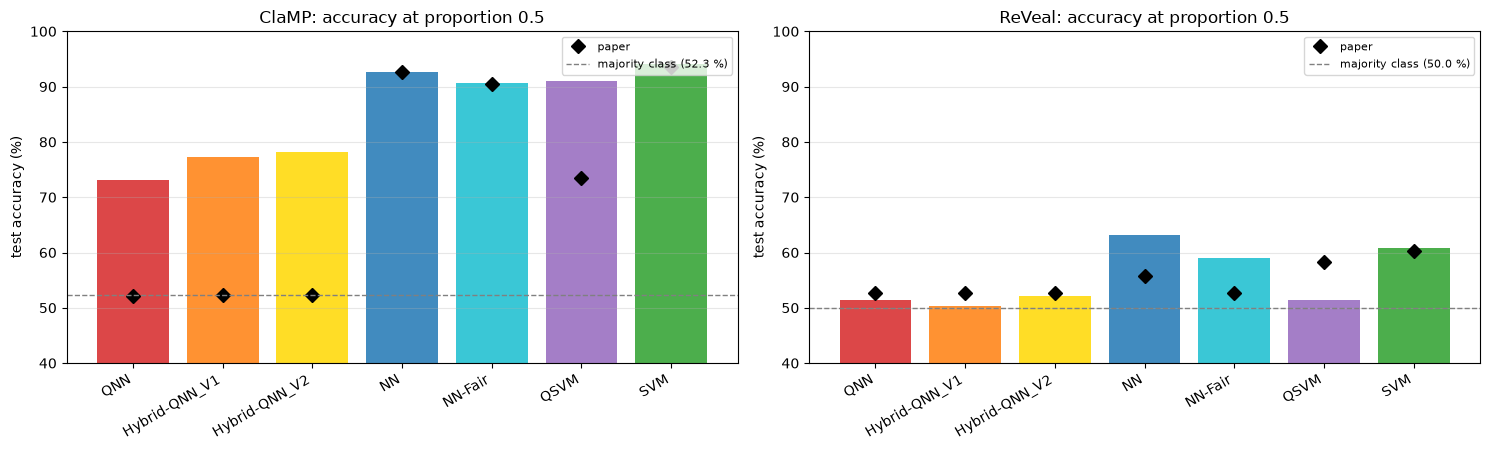

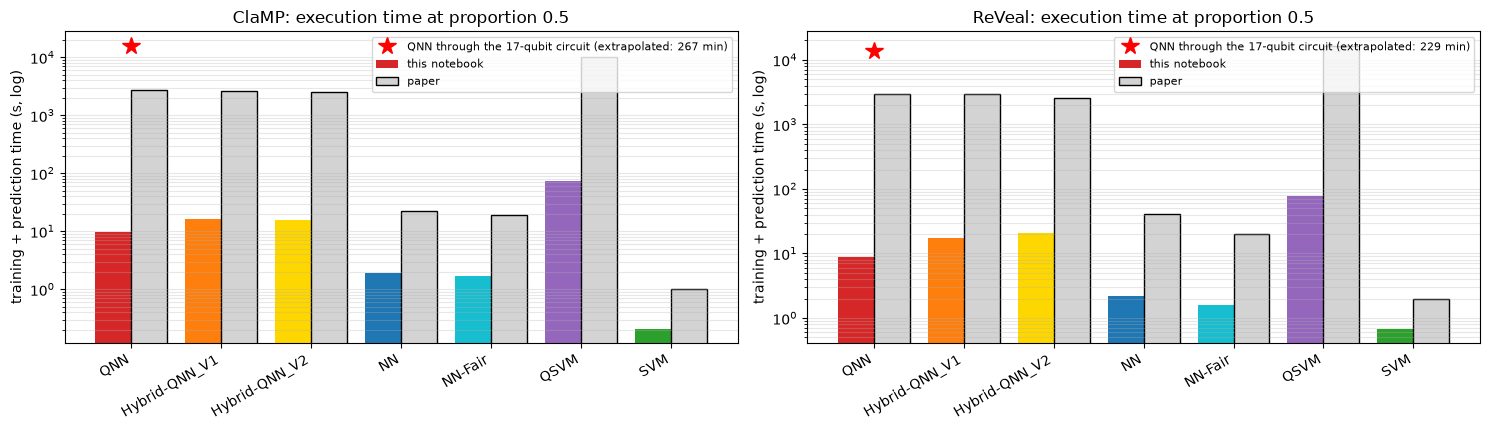

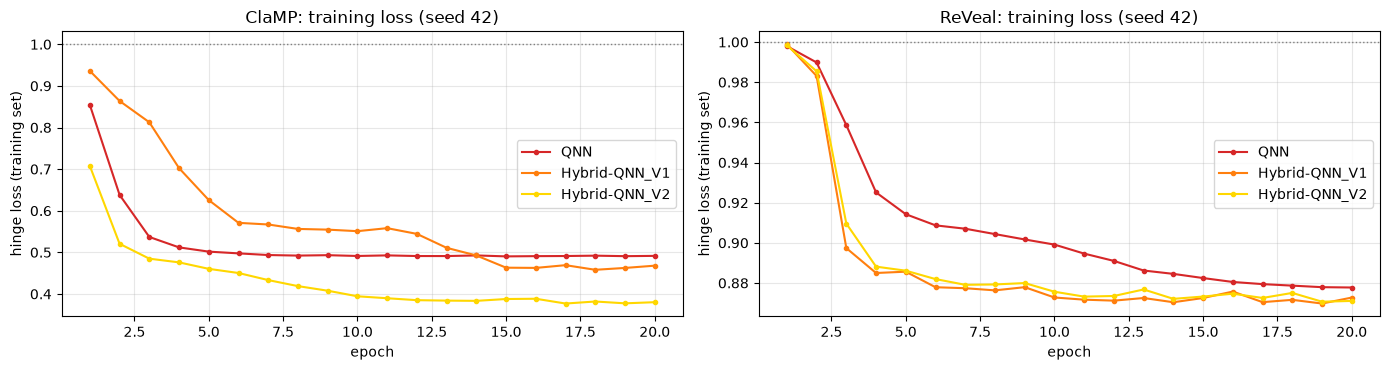

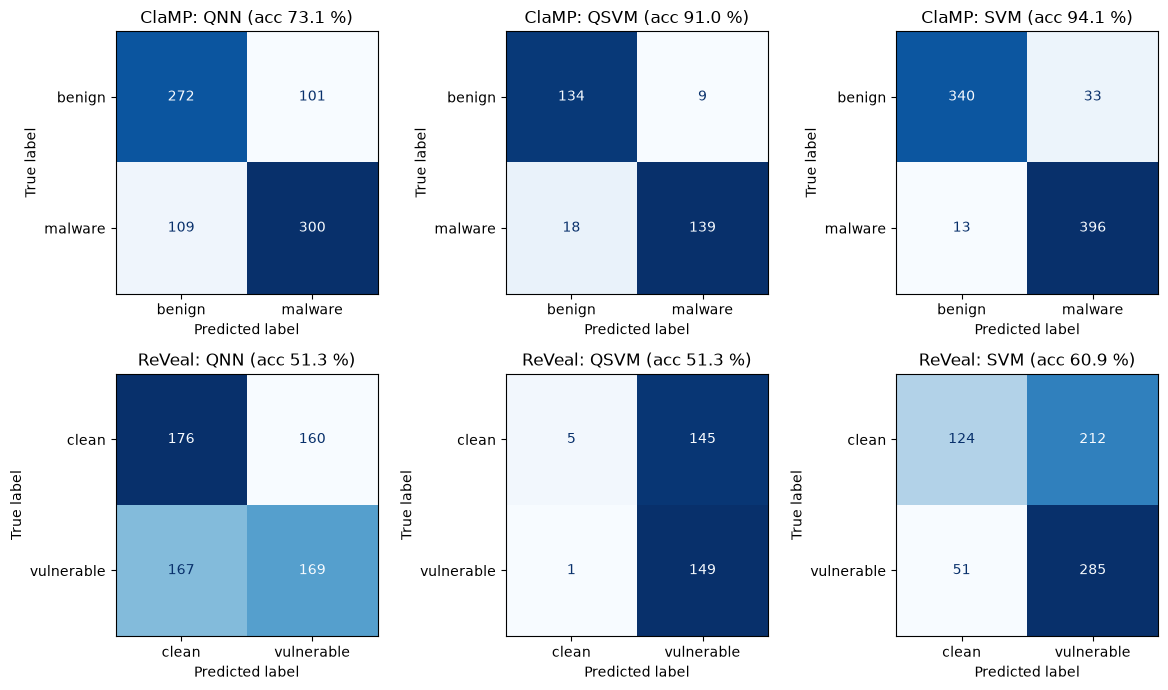

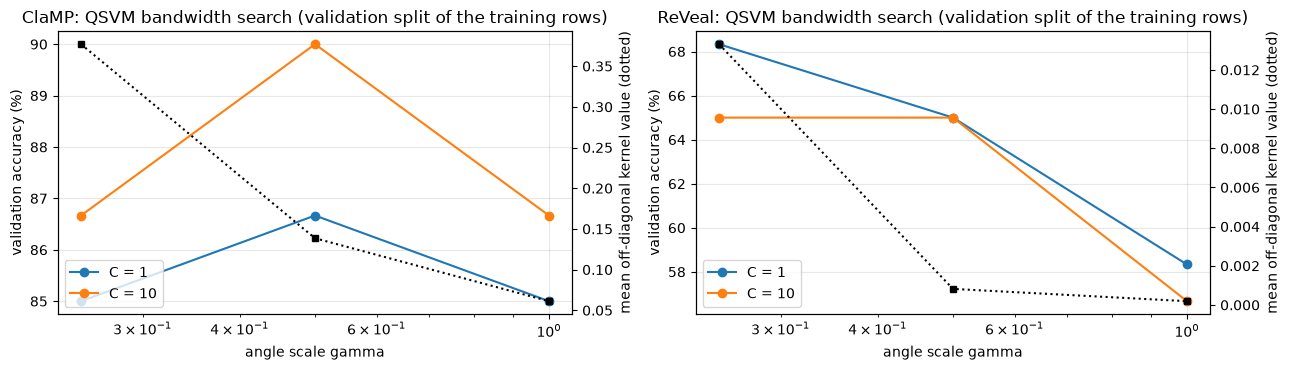

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
colors = {"QNN": "tab:red", "Hybrid-QNN_V1": "tab:orange", "Hybrid-QNN_V2": "gold", "NN": "tab:blue", "NN-Fair": "tab:cyan", "QSVM": "tab:purple", "SVM": "tab:green"}
for ax, ds in zip(axes, BUILDERS):
    for k, (m, i) in enumerate(ORDER):
        g = pick(ds, m, i)
        ax.bar(k, 100 * g.accuracy.mean(), yerr=100 * g.accuracy.std(ddof=0) if len(g) > 1 else None, color=colors[m], capsize=3, alpha=0.85)
        ax.plot(k, PAPER[ds][m][1], "kD", ms=7, label="paper" if k == 0 else None)
    g0 = pick(ds, "SVM", "16 PCs"); maj = 100 * max(g0.tp.iloc[0] + g0.fn.iloc[0], g0.tn.iloc[0] + g0.fp.iloc[0]) / g0.n_test.iloc[0]
    ax.axhline(maj, color="gray", ls="--", lw=1, label=f"majority class ({maj:.1f} %)")
    ax.set_xticks(range(len(ORDER))); ax.set_xticklabels([m for m, _ in ORDER], rotation=30, ha="right"); ax.set_ylim(40, 100)
    ax.set_ylabel("test accuracy (%)"); ax.set_title(f"{ds}: accuracy at proportion {P_REF}"); ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

# execution time: ours, the QNN as it would run through the 17-qubit circuit, and the paper's
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, ds in zip(axes, BUILDERS):
    ours_t = [pick(ds, m, i).time_s.mean() for m, i in ORDER]
    ax.bar(np.arange(len(ORDER)) - 0.2, ours_t, 0.4, color=[colors[m] for m, _ in ORDER], label="this notebook")
    ax.bar(np.arange(len(ORDER)) + 0.2, [PAPER[ds][m][2] for m, _ in ORDER], 0.4, color="lightgray", edgecolor="k", label="paper")
    ntr = int(pick(ds, "QNN", "16 bits").n_train.iloc[0])
    sim_t = EPOCHS * ntr * SIM_MS_PER_ROW / 1000.0
    ax.plot([0], [sim_t], "r*", ms=13, label=f"QNN through the 17-qubit circuit (extrapolated: {sim_t / 60:.0f} min)")
    ax.set_yscale("log"); ax.set_xticks(range(len(ORDER))); ax.set_xticklabels([m for m, _ in ORDER], rotation=30, ha="right")
    ax.set_ylabel("training + prediction time (s, log)"); ax.set_title(f"{ds}: execution time at proportion {P_REF}"); ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both", axis="y")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, ds in zip(axes, BUILDERS):
    for m in ("QNN", "Hybrid-QNN_V1", "Hybrid-QNN_V2"):
        ax.plot(range(1, EPOCHS + 1), loss_curves[(ds, P_REF, m)], "o-", ms=3, color=colors[m], label=m)
    ax.axhline(1.0, color="gray", ls=":", lw=1); ax.set_xlabel("epoch"); ax.set_ylabel("hinge loss (training set)"); ax.set_title(f"{ds}: training loss (seed {SEED})"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for r, ds in enumerate(BUILDERS):
    for c, (m, i) in enumerate([("QNN", "16 bits"), ("QSVM", "16 angles"), ("SVM", "16 PCs")]):
        yt, yp = preds[(ds, P_REF, SEED, m, i)]
        ConfusionMatrixDisplay(confusion_matrix(yt, yp, labels=[0, 1]),
                               display_labels=["benign" if ds == "ClaMP" else "clean", "malware" if ds == "ClaMP" else "vulnerable"]).plot(ax=axes[r, c], colorbar=False, cmap="Blues")
        axes[r, c].set_title(f"{ds}: {m} (acc {100 * accuracy_score(yt, yp):.1f} %)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, ds in zip(axes, BUILDERS):
    tune = qsvm_tune[(ds, SEED)]
    for C, grp in tune.groupby("C"):
        ax.plot(grp["gamma"], 100 * grp["val_accuracy"], "o-", label=f"C = {C:g}")
    ax2 = ax.twinx(); ax2.plot(tune.groupby("gamma")["mean_offdiag_kernel"].first(), "k:", marker="s", ms=4)
    ax2.set_ylabel("mean off-diagonal kernel value (dotted)"); ax.set_xscale("log"); ax.set_xlabel("angle scale gamma"); ax.set_ylabel("validation accuracy (%)")
    ax.set_title(f"{ds}: QSVM bandwidth search (validation split of the training rows)"); ax.legend(loc="lower left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

if len(PROPORTIONS) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, ds in zip(axes, BUILDERS):
        for m, i in ORDER:
            g = results[(results.dataset == ds) & (results.model == m) & (results.inputs == i)].groupby("proportion").accuracy_pct.agg(["mean", "std"])
            ax.errorbar(g.index, g["mean"], yerr=g["std"].fillna(0), marker="o", color=colors[m], label=m, capsize=2)
        ax.set_xlabel("proportion of the dataset"); ax.set_ylabel("test accuracy (%)"); ax.set_title(f"{ds}: accuracy versus dataset size"); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## 7. Side by side with the paper: a verdict for every claim

Tolerance: an accuracy is "reproduced" if it is within **2 percentage points** of the paper's value; otherwise it is "not reached" (ours is lower) or
"exceeded" (ours is higher), with the gap. Parameter counts must match exactly. Execution times depend on the machine, the simulator and the
shot/gradient settings, so absolute seconds are marked "cannot be checked"; the paper's *qualitative* claim (the quantum versions are far slower)
is checked as a ratio instead. The QNN's time through the real circuit is extrapolated from the measured gradient cost per row in the circuit section.

**Note on this committed run.** It is the `FAST_MODE = True` run: the comparison is made at proportion 0.5 with one seed, the QSVM uses 300 training and 300 test rows, and Doc2Vec was trained for 25 epochs (paper: 50), so the verdicts are indicative; the paper's tables are for the entire datasets.

In [17]:
def verdict(paper, ours, tol=2.0):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})"

def acc(ds, m):  return 100 * pick(ds, m, dict(ORDER)[m]).accuracy.mean()
def tim(ds, m):  return pick(ds, m, dict(ORDER)[m]).time_s.mean()
def ntrain(ds):  return int(pick(ds, "QNN", "16 bits").n_train.iloc[0])
def maj_share(ds):
    g = pick(ds, "SVM", "16 PCs").iloc[0]; return 100 * max(g.tp + g.fn, g.tn + g.fp) / g.n_test

V = []
where = f"proportion {P_REF}" + ("" if P_REF == 1.0 else " (the paper's tables are for the entire dataset)")
for ds in BUILDERS:
    for m, i in ORDER:                                                                          # 1. accuracies (Tables 2 and 3)
        V.append((f"{ds}: {m} accuracy (%)", PAPER[ds][m][1], f"{acc(ds, m):.1f}", verdict(PAPER[ds][m][1], acc(ds, m))))
    for m in ("QNN", "Hybrid-QNN_V1", "Hybrid-QNN_V2", "NN", "NN-Fair"):                       # 2. parameter counts
        ours_p = int(pick(ds, m, dict(ORDER)[m]).params.iloc[0]); pp = PAPER[ds][m][0]
        V.append((f"{ds}: {m} parameters", pp, ours_p, "reproduced" if ours_p == pp else f"not reached ({ours_p} vs {pp}; see table of choices)"))
for ds in BUILDERS:                                                                             # 3. qualitative claims
    pq, pc = PAPER[ds], None
    if ds == "ClaMP":
        gap_s, gap_n = acc(ds, "SVM") - acc(ds, "QSVM"), acc(ds, "NN") - acc(ds, "QNN")
        pgap_s, pgap_n = pq["SVM"][1] - pq["QSVM"][1], pq["NN"][1] - pq["QNN"][1]
        for nm, g, pg in [("SVM - QSVM", gap_s, pgap_s), ("NN - QNN", gap_n, pgap_n)]:
            v = verdict(pg, g) if g > 2 else "not reached (no clear classical advantage)"
            V.append((f"ClaMP: classical beats quantum, accuracy gap {nm} (points)", f"{pg:.1f}", f"{g:.1f}", ("direction reproduced; magnitude: " + v) if (g > 2 and v != "reproduced") else v))
    else:
        for nm, a, b, pa, pb in [("SVM - QSVM", "SVM", "QSVM", pq["SVM"][1], pq["QSVM"][1]), ("NN - QNN", "NN", "QNN", pq["NN"][1], pq["QNN"][1])]:
            g, pg = acc(ds, a) - acc(ds, b), pa - pb
            V.append((f"ReVeal: accuracies of quantum and classical are close, gap {nm} (points)", f"{pg:.1f}", f"{g:.1f}", "reproduced" if abs(g) <= 5.0 else f"not reached (gap {g:.1f} > 5)"))
    q_acc = acc(ds, "QNN"); mj = maj_share(ds)
    V.append((f"{ds}: QNN is no better than the majority class ({mj:.1f} %)", f"{pq['QNN'][1]:.1f}", f"{q_acc:.1f}",
              "reproduced" if q_acc - mj <= 2.0 else f"not reproduced (QNN {q_acc - mj:+.1f} points above the majority class)"))
    r_s = tim(ds, "QSVM") / tim(ds, "SVM"); pr_s = pq["QSVM"][2] / pq["SVM"][2]
    V.append((f"{ds}: QSVM is much slower than SVM (time ratio, > 10x counts)", f"{pr_s:,.0f}x", f"{r_s:,.0f}x", "reproduced" if r_s > 10 else f"not reproduced ({r_s:.1f}x)"))
    sim_t = EPOCHS * ntrain(ds) * SIM_MS_PER_ROW / 1000.0; r_n = sim_t / tim(ds, "NN"); pr_n = pq["QNN"][2] / pq["NN"][2]
    V.append((f"{ds}: QNN is much slower than NN (circuit-simulator time / NN time, > 10x counts)", f"{pr_n:,.0f}x", f"{r_n:,.0f}x", "reproduced" if r_n > 10 else f"not reproduced ({r_n:.1f}x)"))
    for m in ("QNN", "QSVM", "NN", "SVM"):                                                       # 4. absolute seconds
        V.append((f"{ds}: {m} execution time (s)", pq[m][2], f"{tim(ds, m):.1f}", "cannot be checked (machine / simulator dependent)"))
exv = {ds: main[ds]["explained"] for ds in BUILDERS}
V.append(("PCA(16) holds 98 %, 99 % and 75 % of the variance of 'the three datasets'", "98 / 99 / 75 %", f"standardised: ClaMP {100 * exv['ClaMP']:.0f} %, ReVeal {100 * exv['ReVeal']:.0f} %",
          "cannot be checked (datasets not named; standardise-then-PCA gives a different share on ClaMP, see text)"))
V.append(("Real quantum hardware results", "none (simulators only)", "none", "cannot be checked (the paper reports none)"))
verd = pd.DataFrame(V, columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 120)
display(verd)
kinds = verd["Verdict"].str.extract(r"^(reproduced|direction reproduced|not reached|not reproduced|exceeded|cannot be checked)")[0].value_counts()
print("verdict counts:", kinds.to_dict(), "| compared on", where)

,Claim,Paper,This notebook,Verdict
0,ClaMP: QNN accuracy (%),52.1,73.1,exceeded (+21.0)
1,ClaMP: Hybrid-QNN_V1 accuracy (%),52.27,77.2,exceeded (+25.0)
2,ClaMP: Hybrid-QNN_V2 accuracy (%),52.27,78.1,exceeded (+25.9)
3,ClaMP: NN accuracy (%),92.7,92.6,reproduced
4,ClaMP: NN-Fair accuracy (%),90.5,90.7,reproduced
5,ClaMP: QSVM accuracy (%),73.5,91.0,exceeded (+17.5)
6,ClaMP: SVM accuracy (%),93.5,94.1,reproduced
7,ClaMP: QNN parameters,32,32,reproduced
8,ClaMP: Hybrid-QNN_V1 parameters,45,45,reproduced
9,ClaMP: Hybrid-QNN_V2 parameters,63,63,reproduced


verdict counts: {'reproduced': 20, 'cannot be checked': 10, 'exceeded': 6, 'not reached': 5, 'direction reproduced': 2, 'not reproduced': 1} | compared on proportion 0.5 (the paper's tables are for the entire dataset)


In [18]:
# ClaMP: how much of the variance does PCA(16) keep if the columns are NOT standardised first? (the paper's 98 % / 99 % are much higher than our standardised share)
yC = clamp["class"].values; tr_ids, te_ids = _clamp_split[SEED]                      # the full 70 / 30 split of the main seed
enc = ColumnTransformer([("packer", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["packer_type"]),
                         ("num", "passthrough", CLAMP_NUMERIC)]).fit(clamp.iloc[tr_ids][CLAMP_FEATURES])
Ftr_, Fte_ = enc.transform(clamp.iloc[tr_ids][CLAMP_FEATURES]), enc.transform(clamp.iloc[te_ids][CLAMP_FEATURES])
sc_ = StandardScaler().fit(Ftr_)
pca_std = PCA(N_QUBITS, random_state=SEED).fit(sc_.transform(Ftr_)); pca_raw = PCA(N_QUBITS, random_state=SEED).fit(Ftr_)
print(f"ClaMP (100 % split), PCA(16) explained variance: standardise first {100 * pca_std.explained_variance_ratio_.sum():.1f} %  |  PCA on the unscaled columns {100 * pca_raw.explained_variance_ratio_.sum():.4f} %")
for name, pca, A, B in [("standardise then PCA (this notebook)", pca_std, sc_.transform(Ftr_), sc_.transform(Fte_)), ("PCA on the unscaled columns", pca_raw, Ftr_, Fte_)]:
    Rtr, Rte = pca.transform(A), pca.transform(B)
    print(f"  {name}: SVM (rbf) test accuracy {100 * SVC().fit(Rtr, yC[tr_ids]).score(Rte, yC[te_ids]):.1f} %")

ClaMP (100 % split), PCA(16) explained variance: standardise first 42.7 %  |  PCA on the unscaled columns 100.0000 %


  standardise then PCA (this notebook): SVM (rbf) test accuracy 95.6 %


  PCA on the unscaled columns: SVM (rbf) test accuracy 74.0 %


## 8. Reading the paper critically

*The numbers below are from the committed `FAST_MODE = True` run: proportion 50 % of each dataset, one seed (42), QSVM on 300 training and 300 test rows. They show the pattern; they are not a replacement for the full protocol (3 seeds, all three sizes, QSVM on every row), which was not executed here.*

**What reproduces.** The classical side of the paper is solid and easy to match: on ClaMP the NN (92.6 % vs 92.7 %), the "fair" NN (90.7 % vs 90.5 %) and the SVM (94.1 % vs 93.5 %) land within the 2-point tolerance, with exactly the paper's parameter counts (177 and 73). The ReVeal SVM (60.9 % vs 60.34 %) also matches, and ReVeal is hard for every model: all accuracies sit between 50 % and 64 %. The paper's qualitative message that the simulated quantum models cost orders of magnitude more run time than the classical ones is also reproduced (here the QSVM kernel is 100-350x slower than the SVM even with an exact vectorised simulator, and the 17-qubit circuit would take hours per training run).

**What does not reproduce, and why it matters.**
* *The ClaMP quantum numbers are much better here than in the paper.* The QNN reaches 73 % (paper 52.1 %, which is the share of malware in the data, i.e. a constant prediction), the hybrids 77-78 % (paper 52.27 %), and the QSVM 91 % even with only 300 training rows (paper 73.5 %). The paper's headline gap of 20-40 points between quantum and classical models on ClaMP shrinks to 3 points (SVM vs QSVM) and 19 points (NN vs QNN). The measured gaps point the same way as the paper's, but a reader who takes the paper's gap as a property of QML would be wrong: it is largely a property of how the inputs were encoded and how the models were set up.
* *Encoding is decisive and the paper says too little about it.* The QNN sees only 16 bits (the sign of each principal component); a random forest on the same bits still reaches 94 %, so the data are not the limit, the circuit is. The QSVM needs its angles shrunk (the bandwidth search chose 0.5 on ClaMP and 0.25 on ReVeal; see the bandwidth figure and the mean off-diagonal kernel value): in the validation search the largest scale (1.0) was the worst on both datasets (ClaMP 85-87 % against 90 % at the chosen scale, ReVeal 57-58 % against 68 %), and the mean off-diagonal kernel value falls toward zero as the scale grows, the usual signature of kernel concentration. (On ReVeal the chosen setting reached 68 % on 60 validation rows but only 51 % on the test rows: the search set is tiny and the signal weak.) The paper reports neither the feature map nor the angle scaling, so its 73.5 % cannot be told apart from "QSVM with an unlucky bandwidth".
* *The PCA claim is inconsistent with the rest of the pipeline.* The paper says 16 components keep 98 % and 99 % of the variance. After standardising 108 columns, 16 components keep only 43 % of the ClaMP variance here; PCA on the unscaled columns keeps 100 %, but then the SVM on those components falls to 74 %, while the paper's 93.5 % SVM matches the standardise-then-PCA pipeline (95.6 % on the full 70 / 30 split). Which step order the authors used cannot be recovered from the text. (The ReVeal Doc2Vec space is nearly two-dimensional in variance terms: 16 PCs hold 99 % in our PV-DBOW embedding.)
* *ReVeal is close to unlearnable with 16 numbers and these embeddings.* Our classical models do better than the paper's NNs (63 % and 59 % vs 55.7 % and 52.74 %), the QSVM falls to chance (51.3 %, it predicts almost every function as vulnerable) and the QNN and hybrids stay at chance as in the paper. The paper's remark that quantum and classical accuracy are "approximately similar" on ReVeal holds only because everything is near chance; here the classical models are 9-12 points ahead of the quantum ones. Function length alone separates the classes better than most of this signal (vulnerable functions have a median of 284 tokens against 108 for clean ones), which is a dataset artefact a Doc2Vec + PCA pipeline can pick up without understanding vulnerabilities.

**Weaknesses of the paper as an experiment.**
* Single runs and no confidence intervals. With 100-300 test rows or a single split, differences of a few points (the 52.27 % vs 52.1 % comparisons) carry no information, and the paper's identical 52.71 % for all QNN variants indicates a constant prediction (in our run the ReVeal training hinge loss only falls from 1.0 to about 0.87 in 20 epochs, barely beyond chance).
* "Execution time" mixes unlike things: a shot-based or tensor-network simulator with a Keras graph against scikit-learn. The paper's 10,000 s for the QSVM measures the simulator's overhead, not an intrinsic property of quantum kernels; an exact statevector on 16 qubits needs minutes (here), and the factor to the classical SVM shrinks accordingly.
* No hardware, no noise. The paper concludes that "current versions with limited number of qubits" are not good enough, but 16 qubits are simulated exactly; the limitation it describes is the simulator's cost and the encoding, not the qubit count.
* The data split embeds Doc2Vec before splitting, and the ReVeal text swaps the class names (2,240 non-vulnerable vs 20,494 vulnerable); both are fixable but point to limited quality control.

**Our own caveats.** Doc2Vec is a PyTorch PV-DBOW re-implementation (first 64 tokens, 25 epochs here, 50 in the full protocol) because gensim is not installed; the QNN is the TensorFlow-Quantum tutorial circuit in PennyLane, trained through an exact closed form that is asserted equal to the 17-qubit circuit; the QSVM feature map, kernel bandwidth and the bit threshold are our choices; the committed run uses one seed.

## 9. Exercises

1. **Bandwidth.** Add `gamma = 2.0` and `4.0` to `QSVM_GAMMAS` and watch the mean off-diagonal kernel value. At which scale does the Gram matrix become almost the identity, and what does that do to the test accuracy?
2. **Entanglement.** Change the feature map to `entanglement="full"` or `reps=1` (the kernel code is generic only for the linear map: extend `ZXOR` and `PAIRS`) and compare accuracy and time.
3. **Encoding.** The QNN sees 16 bits. Replace the sign threshold by 2 bits per component (quartiles, 32 qubits is too many: use 8 components x 2 bits) and check whether the QNN improves.
4. **Circuit expressivity.** The QNN output is a product of 16 factors. Add a second readout-qubit layer (for example an `IsingYY` layer) in `qnn_circuit`, re-derive or drop the closed form, and train through the simulator for two epochs on a small subset.
5. **Doc2Vec.** Replace the PV-DBOW embedding by TF-IDF + truncated SVD to 16 components and compare the classical SVM on ReVeal; then check whether function length alone (one number) separates the two classes as well as the 16 components do.